**1. Importing the dependencies**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from  sklearn.preprocessing  import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pickle


**2. Data Loading & Understanding**

In [2]:
# Load the uploaded train.csv into the 'df' DataFrame
df =   pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Autism_ML_Project/train.csv')

Initial Inspection

In [3]:
df.shape

(800, 22)

In [4]:
df.head()

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,...,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,...,f,?,no,no,Austria,no,6.351166,18 and more,Self,0
1,2,0,0,0,0,0,0,0,0,0,...,m,?,no,no,India,no,2.255185,18 and more,Self,0
2,3,1,1,1,1,1,1,1,1,1,...,m,White-European,no,yes,United States,no,14.851484,18 and more,Self,1
3,4,0,0,0,0,0,0,0,0,0,...,f,?,no,no,United States,no,2.276617,18 and more,Self,0
4,5,0,0,0,0,0,0,0,0,0,...,m,?,no,no,South Africa,no,-4.777286,18 and more,Self,0


In [5]:
df.tail()

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,...,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
795,796,0,1,0,0,0,0,0,0,1,...,m,Hispanic,no,no,New Zealand,no,12.999501,18 and more,Self,0
796,797,0,1,1,0,0,1,0,1,1,...,m,White-European,no,no,Cyprus,no,13.561518,18 and more,Self,0
797,798,0,0,0,0,0,0,0,0,0,...,m,South Asian,yes,no,New Zealand,no,2.653177,18 and more,Self,0
798,799,0,0,0,0,0,0,0,0,0,...,f,?,no,no,Canada,no,9.069342,18 and more,Self,0
799,800,0,1,0,0,0,0,0,0,0,...,f,?,no,no,United Arab Emirates,yes,2.243304,18 and more,Self,0


In [6]:
# display all columns of a dataframe
pd.set_option('display.max_columns', None)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               800 non-null    int64  
 1   A1_Score         800 non-null    int64  
 2   A2_Score         800 non-null    int64  
 3   A3_Score         800 non-null    int64  
 4   A4_Score         800 non-null    int64  
 5   A5_Score         800 non-null    int64  
 6   A6_Score         800 non-null    int64  
 7   A7_Score         800 non-null    int64  
 8   A8_Score         800 non-null    int64  
 9   A9_Score         800 non-null    int64  
 10  A10_Score        800 non-null    int64  
 11  age              800 non-null    float64
 12  gender           800 non-null    str    
 13  ethnicity        800 non-null    str    
 14  jaundice         800 non-null    str    
 15  austim           800 non-null    str    
 16  contry_of_res    800 non-null    str    
 17  used_app_before  800 non-nu

In [8]:
# convert age column datatype to integer
df['age'] = df['age'].astype(int)

In [9]:
# for unique values in each column
for col in df.columns:
  numerical_features = ['ID','age',"result"]
  if col not in numerical_features:
    print(col, df[col].unique())
    print("-"*50)

A1_Score [1 0]
--------------------------------------------------
A2_Score [0 1]
--------------------------------------------------
A3_Score [1 0]
--------------------------------------------------
A4_Score [0 1]
--------------------------------------------------
A5_Score [1 0]
--------------------------------------------------
A6_Score [0 1]
--------------------------------------------------
A7_Score [1 0]
--------------------------------------------------
A8_Score [0 1]
--------------------------------------------------
A9_Score [1 0]
--------------------------------------------------
A10_Score [1 0]
--------------------------------------------------
gender <ArrowStringArray>
['f', 'm']
Length: 2, dtype: str
--------------------------------------------------
ethnicity <ArrowStringArray>
[              '?',  'White-European', 'Middle Eastern ',        'Pasifika',
           'Black',          'Others',        'Hispanic',           'Asian',
         'Turkish',     'South Asian',        

In [10]:
# dropping ID &  age_desc column
df = df.drop(columns = ['ID', 'age_desc'])

In [11]:
df.shape

(800, 20)

In [12]:
df.head(2)

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,f,?,no,no,Austria,no,6.351166,Self,0
1,0,0,0,0,0,0,0,0,0,0,47,m,?,no,no,India,no,2.255185,Self,0


In [13]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='str')

In [14]:
df["contry_of_res"].unique()

<ArrowStringArray>
[             'Austria',                'India',        'United States',
         'South Africa',               'Jordan',       'United Kingdom',
               'Brazil',          'New Zealand',               'Canada',
           'Kazakhstan', 'United Arab Emirates',            'Australia',
              'Ukraine',                 'Iraq',               'France',
             'Malaysia',             'Viet Nam',                'Egypt',
          'Netherlands',          'Afghanistan',                 'Oman',
                'Italy',        'AmericanSamoa',              'Bahamas',
         'Saudi Arabia',              'Ireland',                'Aruba',
            'Sri Lanka',               'Russia',              'Bolivia',
           'Azerbaijan',              'Armenia',               'Serbia',
             'Ethiopia',               'Sweden',              'Iceland',
            'Hong Kong',               'Angola',                'China',
              'Germany',        

In [15]:
# define the mapping dictionary for country names
mapping = {
    "Viet Nam": "Vietnam",
    "AmericanSamoa": "United States",
    "Hong Kong": "China"
}

# replace value in the country column
df["contry_of_res"] = df["contry_of_res"].replace(mapping)

In [16]:
df["contry_of_res"].unique()

<ArrowStringArray>
[             'Austria',                'India',        'United States',
         'South Africa',               'Jordan',       'United Kingdom',
               'Brazil',          'New Zealand',               'Canada',
           'Kazakhstan', 'United Arab Emirates',            'Australia',
              'Ukraine',                 'Iraq',               'France',
             'Malaysia',              'Vietnam',                'Egypt',
          'Netherlands',          'Afghanistan',                 'Oman',
                'Italy',              'Bahamas',         'Saudi Arabia',
              'Ireland',                'Aruba',            'Sri Lanka',
               'Russia',              'Bolivia',           'Azerbaijan',
              'Armenia',               'Serbia',             'Ethiopia',
               'Sweden',              'Iceland',                'China',
               'Angola',              'Germany',                'Spain',
                'Tonga',        

In [17]:
# target class distribution
df["Class/ASD"].value_counts()

Class/ASD
0    639
1    161
Name: count, dtype: int64

**Insights**
1. missing values on ethinicity & relation
2. age_desc column has only 1 unique value. So it is removed as it is not important for prediction. drop age & ID column
3. fixed country names
4. identified class imbalance in the target column

**3. Exploratory Data Analysis (EDA):**

In [18]:
df.describe()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,result,Class/ASD
count,800.000000,800.000000,800.000000,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,0.560000,0.530000,0.450000,0.41500,0.395000,0.303750,0.397500,0.508750,0.495000,0.617500,27.963750,8.537303,0.201250
std,0.496697,0.499411,0.497805,0.49303,0.489157,0.460164,0.489687,0.500236,0.500288,0.486302,16.329827,4.807676,0.401185
min,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,-6.137748,0.000000
25%,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000,5.306575,0.000000
50%,1.000000,1.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,24.000000,9.605299,0.000000
75%,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,35.250000,12.514484,0.000000
max,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,89.000000,15.853126,1.000000


**Univariate Analysis**

Numerical Columns:
- age
- result

In [19]:
# set the desired theme
sns.set_theme(style="darkgrid")

Mean : 27.96375
Median : 24.0


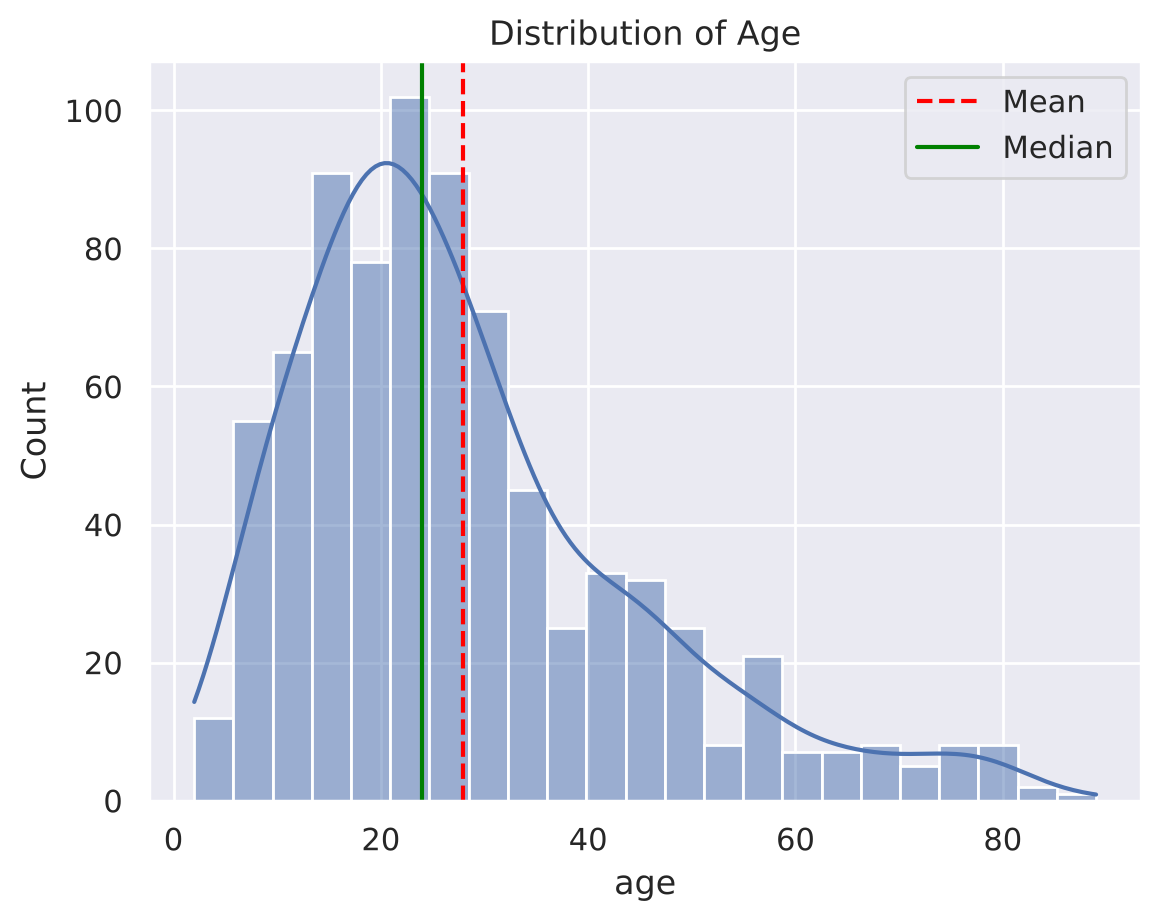

In [20]:
# Histogram for "age"
sns.histplot(df['age'], kde=True)
plt.title("Distribution of Age")

# Calculate mean and median
age_mean = df['age'].mean()
age_median = df['age'].median()

print("Mean :", age_mean)
print("Median :", age_median)

# add vertical lines for mean and median
plt.axvline(age_mean, color='red', linestyle="--", label="Mean")
plt.axvline(age_median, color='green', linestyle="-", label="Median")

plt.legend()

plt.show()

Mean : 8.537303106501248
Median : 9.605299308


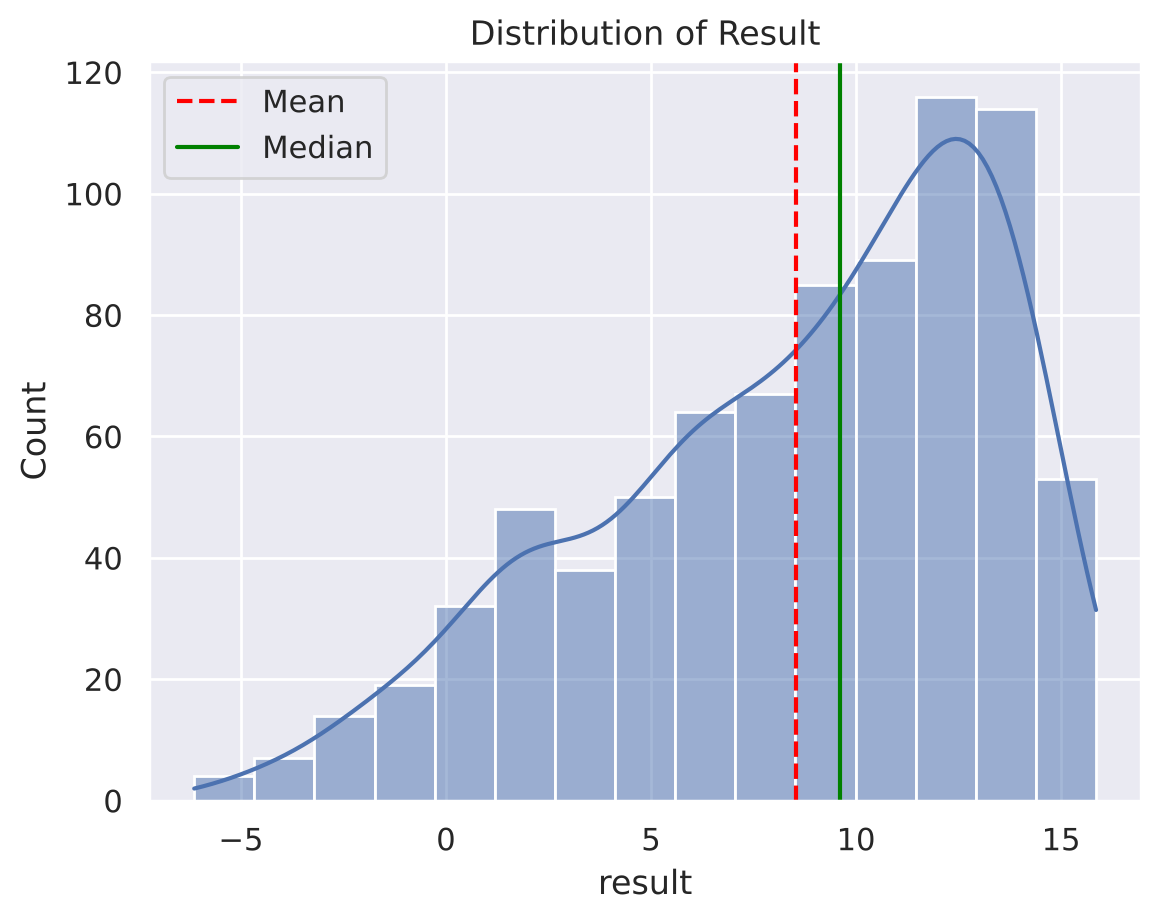

In [21]:
# Histogram for "result"
sns.histplot(df['result'], kde=True)
plt.title("Distribution of Result")

# Calculate mean and median
result_mean = df['result'].mean()
result_median = df['result'].median()

print("Mean :", result_mean)
print("Median :", result_median)

# add vertical lines for mean and median
plt.axvline(result_mean, color='red', linestyle="--", label="Mean")
plt.axvline(result_median, color='green', linestyle="-", label="Median")

plt.legend()

plt.show()

**Box plots for identifyig outliers in the numerical columns**

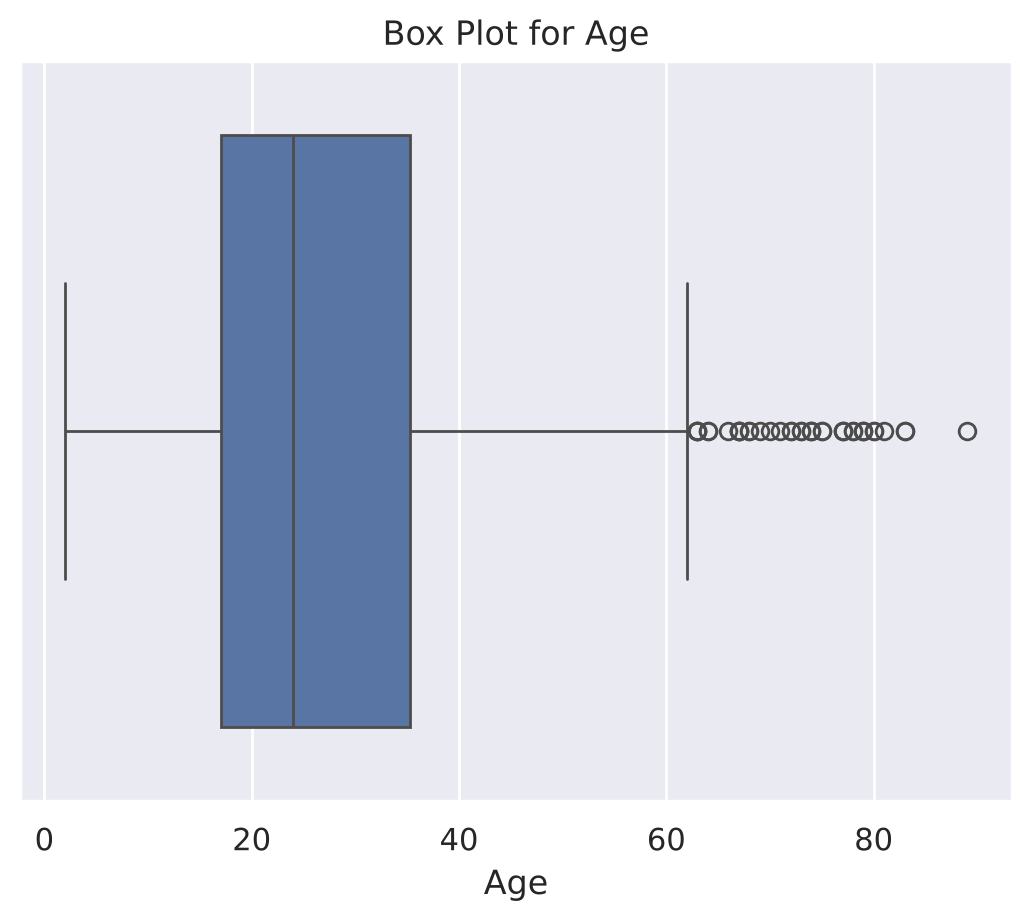

In [22]:
# box plot
sns.boxplot(x=df['age'])
plt.title("Box Plot for Age")
plt.xlabel('Age')
plt.show()

In [23]:
# Calculate Q1, Q3, and IQR for the 'age' column
Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1

# Define the outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[(df['age'] < lower_bound) | (df['age'] > upper_bound)]

print(f"Q1 (25th percentile): {Q1}")
print(f"Q3 (75th percentile): {Q3}")
print(f"IQR: {IQR}")
print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")
print(f"Total number of outliers in 'age' column: {len(outliers)}")

Q1 (25th percentile): 17.0
Q3 (75th percentile): 35.25
IQR: 18.25
Lower Bound: -10.375
Upper Bound: 62.625
Total number of outliers in 'age' column: 39


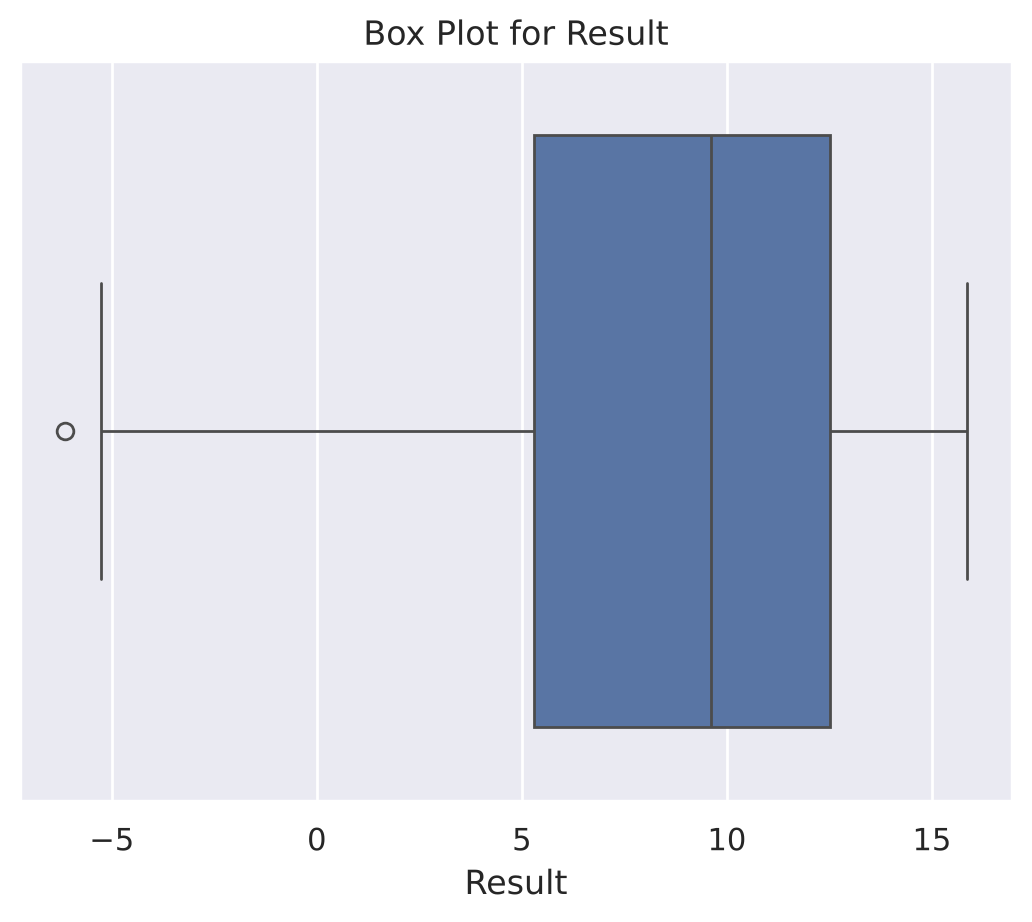

In [24]:
# box plot
sns.boxplot(x=df['result'])
plt.title("Box Plot for Result")
plt.xlabel('Result')
plt.show()

In [25]:
# count the outliers for 'result' column
Q1 = df['result'].quantile(0.25)
Q3 = df['result'].quantile(0.75)
IQR = Q3 - Q1

# define outliers boundaries
lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR

# identify outliers
outliers = df[(df['result'] < lower_bound) | (df['result'] > upper_bound)]

print(f"total number of outliers present in 'result' column: {len(outliers)}")


total number of outliers present in 'result' column: 1


Univariate analysis of Categorical columns

In [26]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='str')

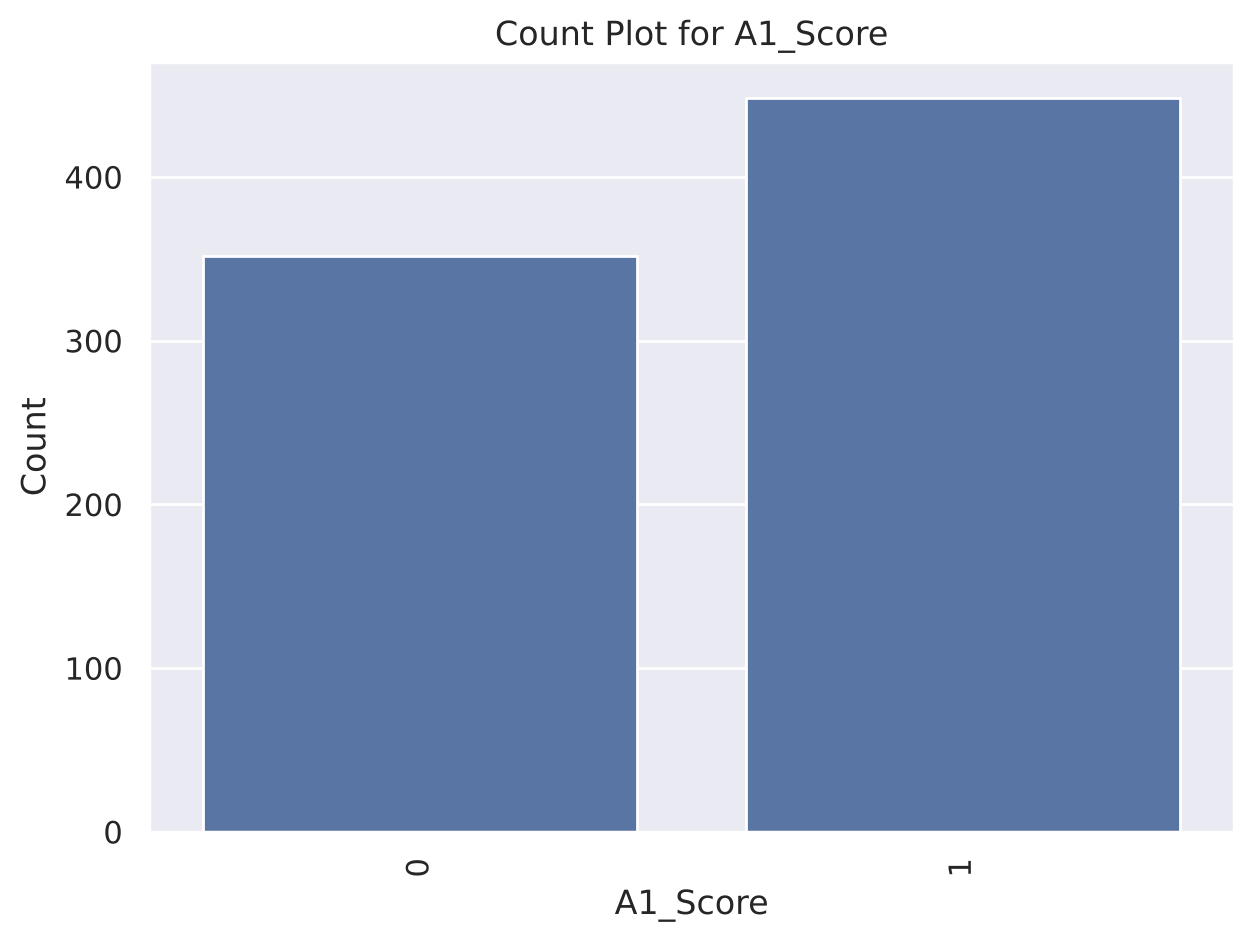

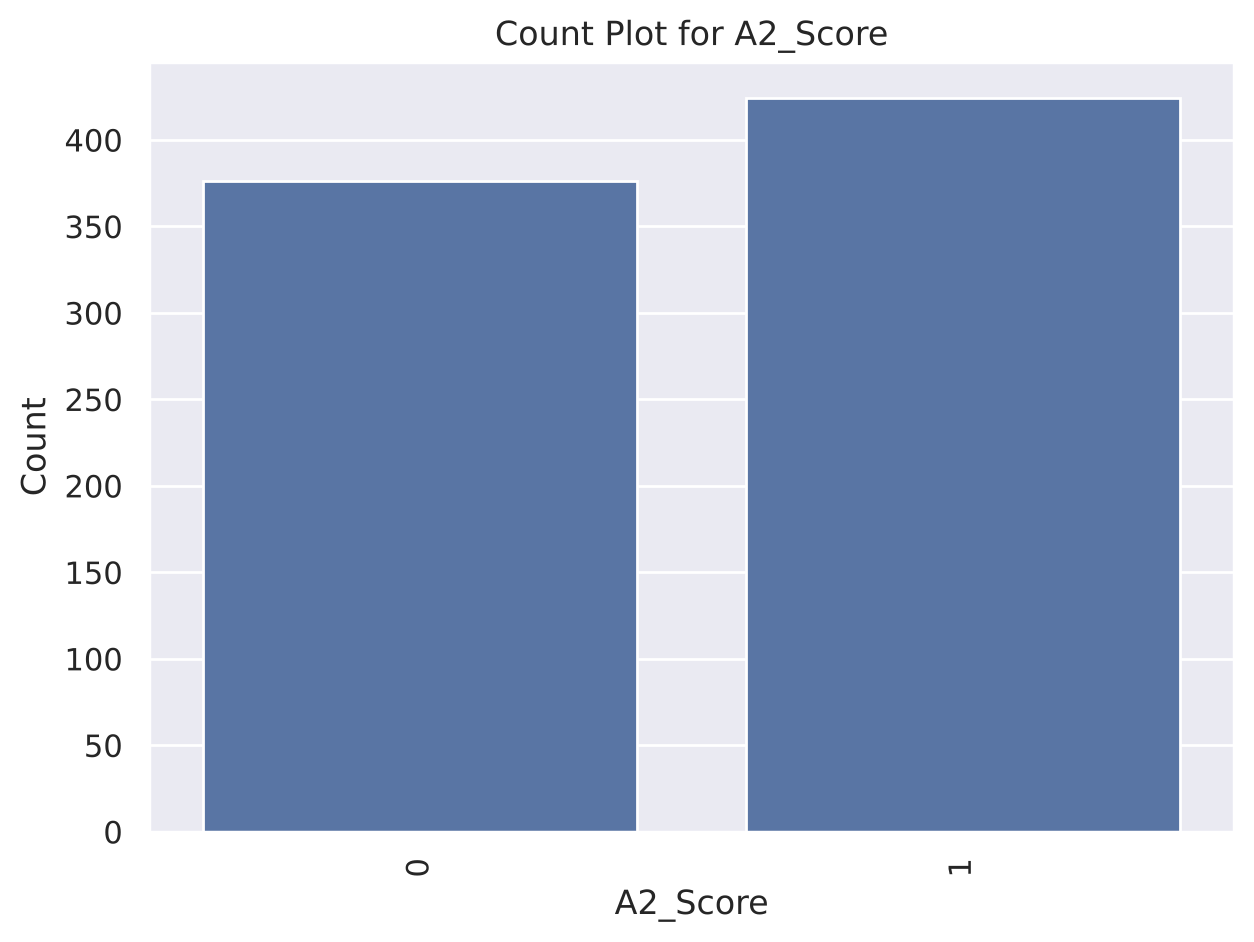

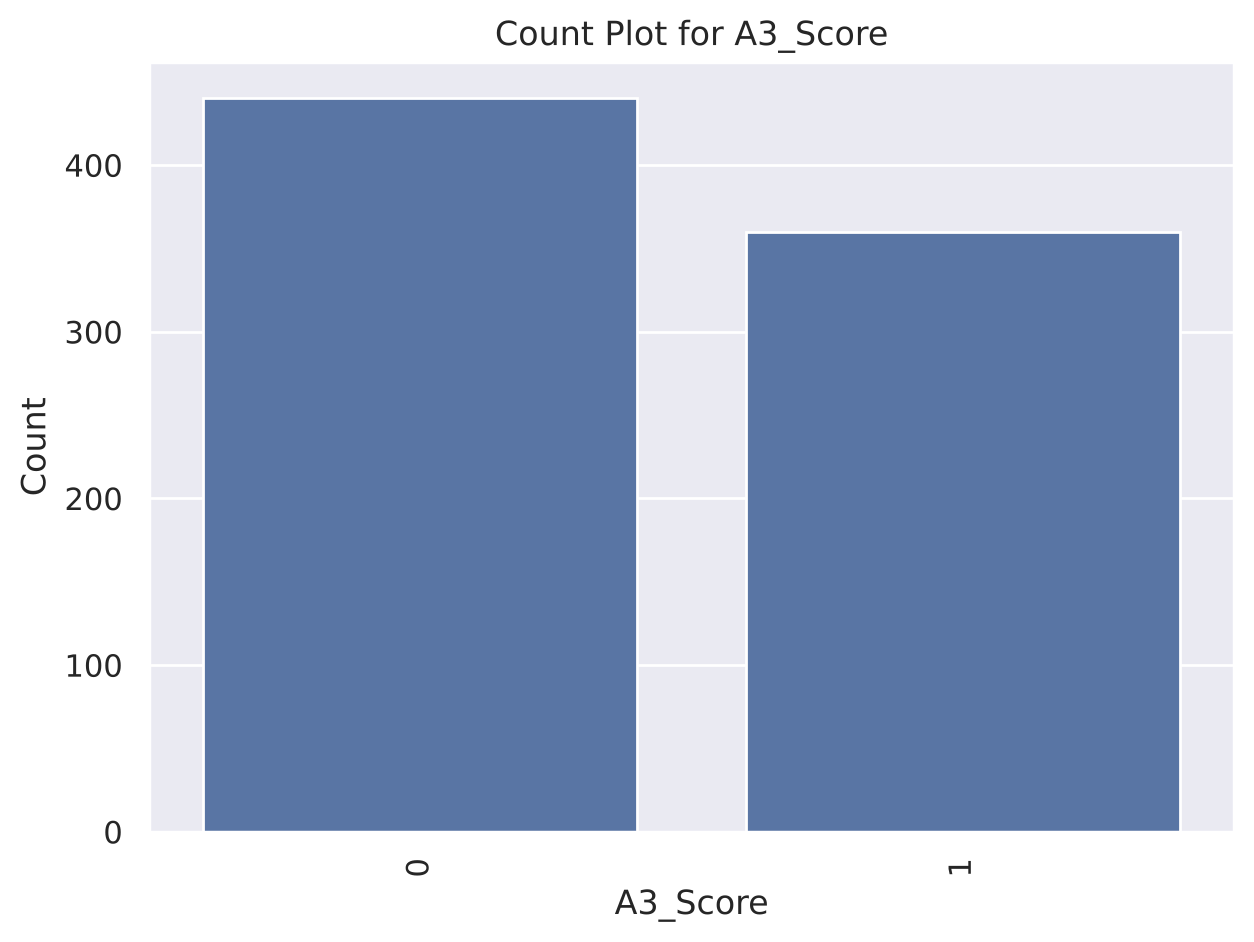

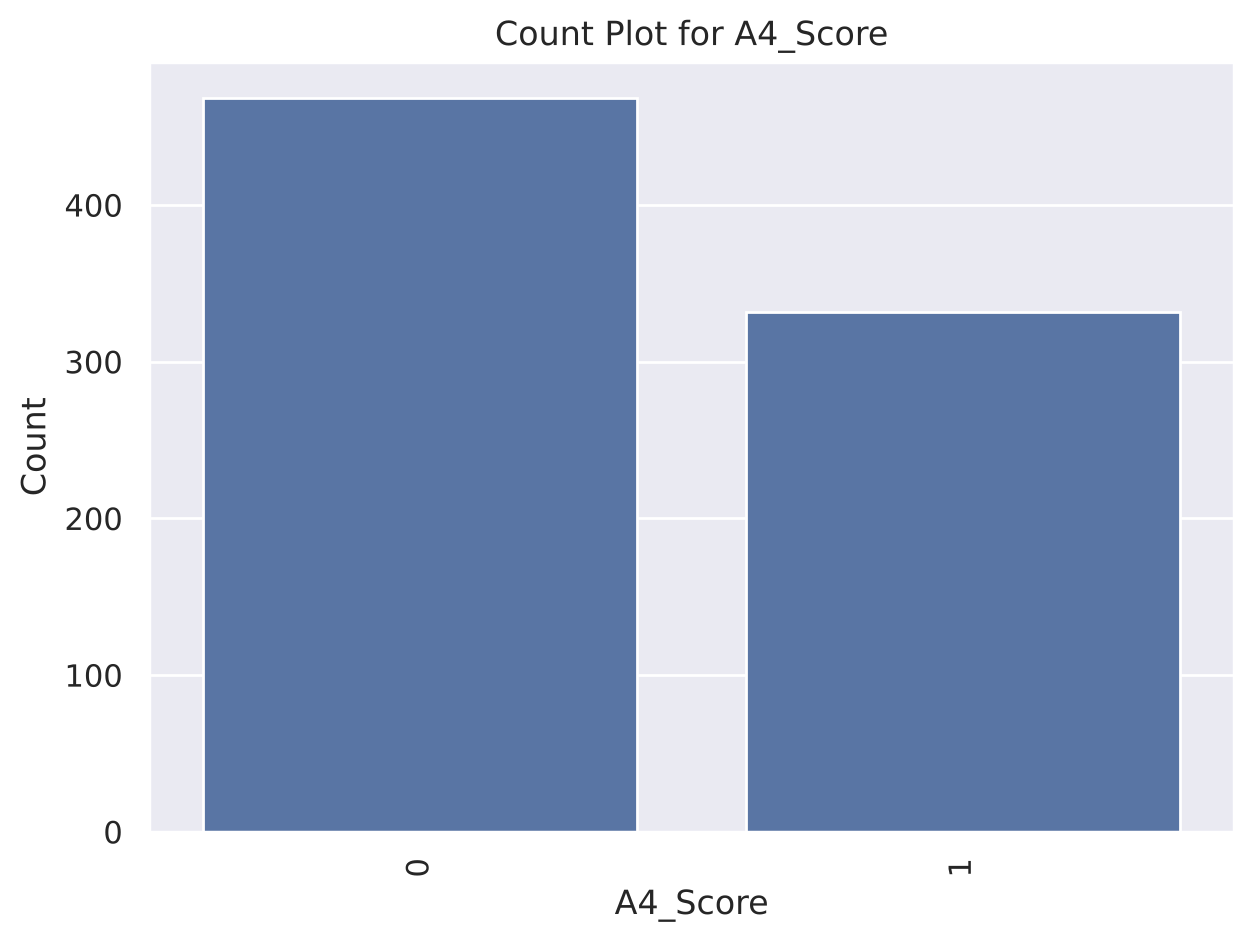

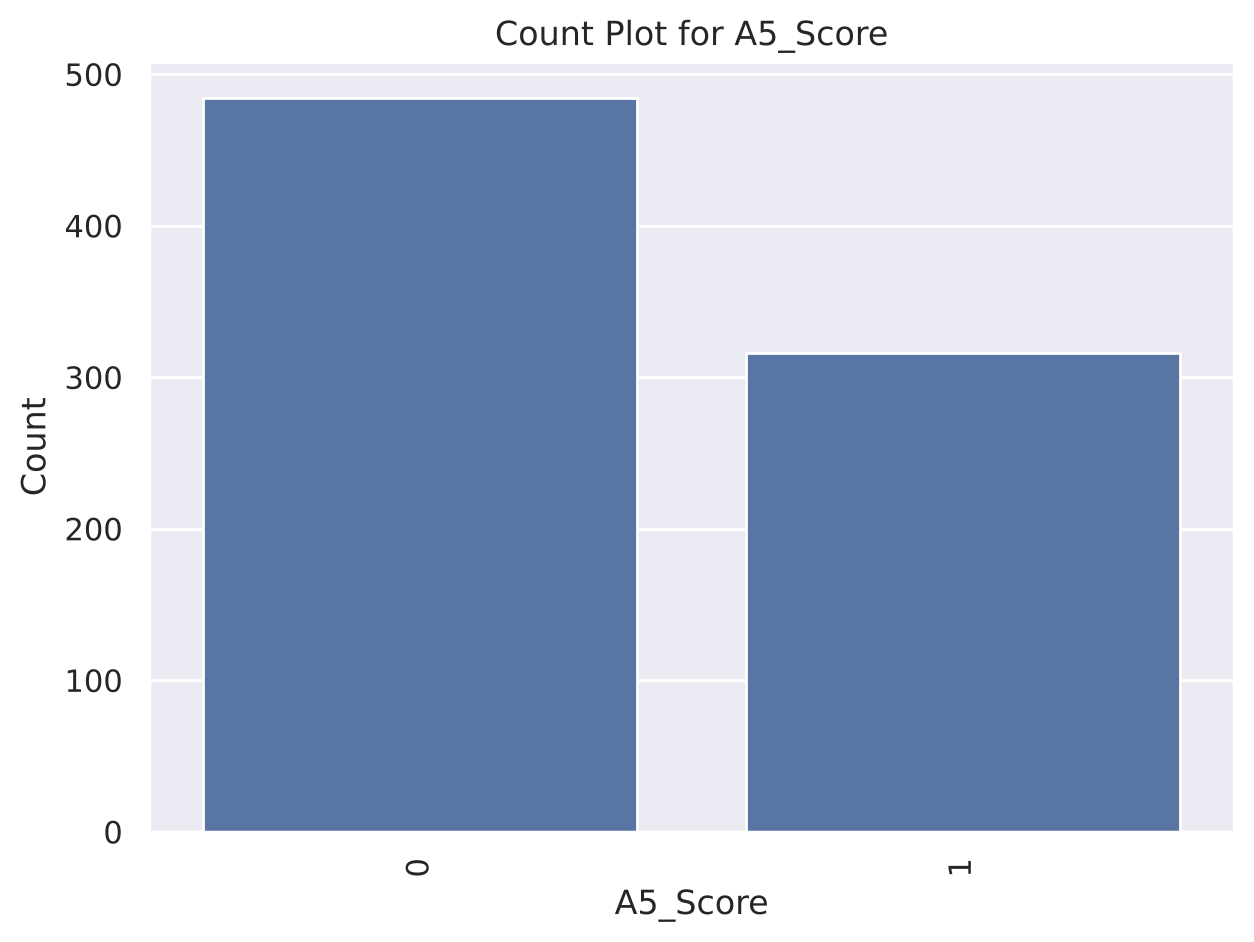

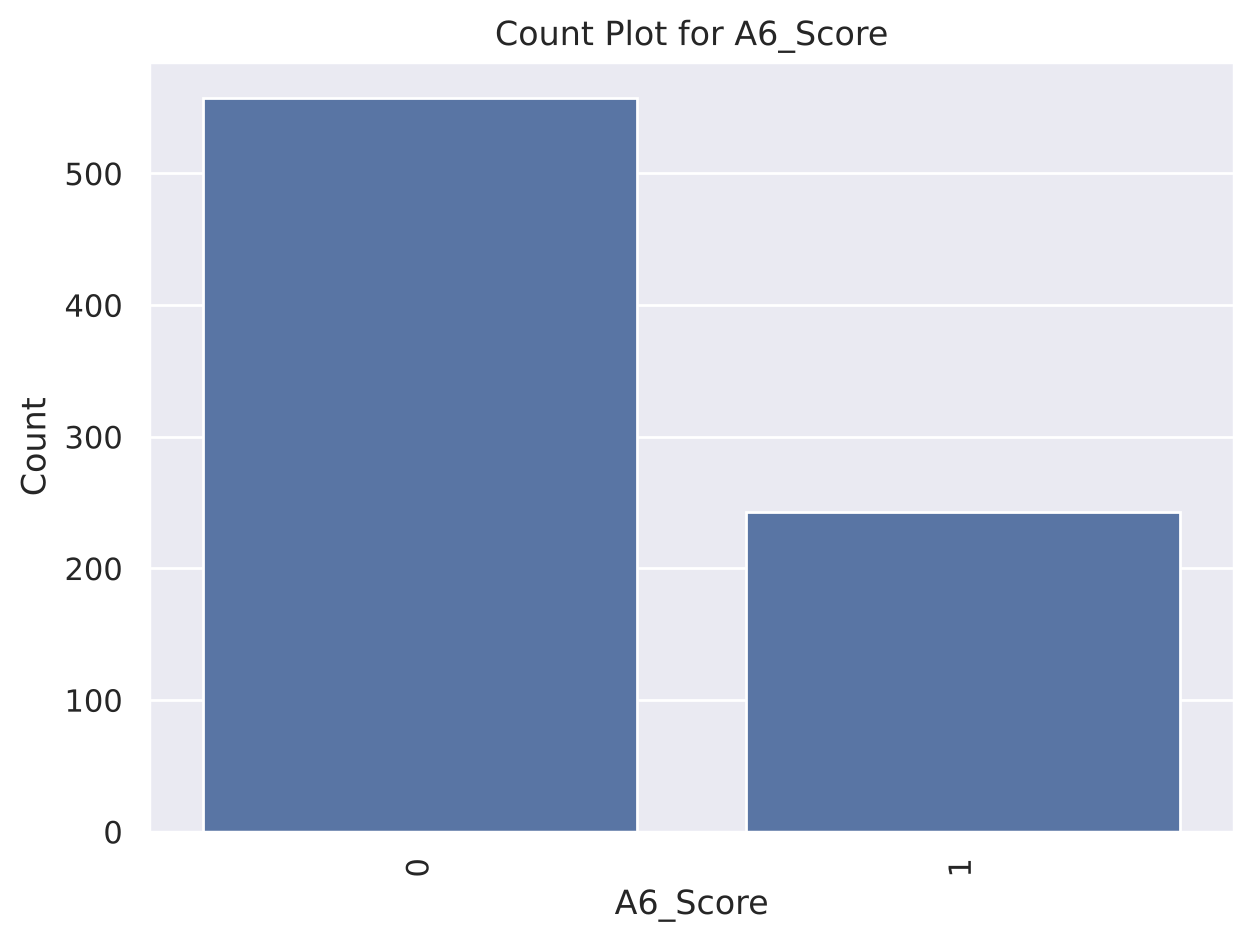

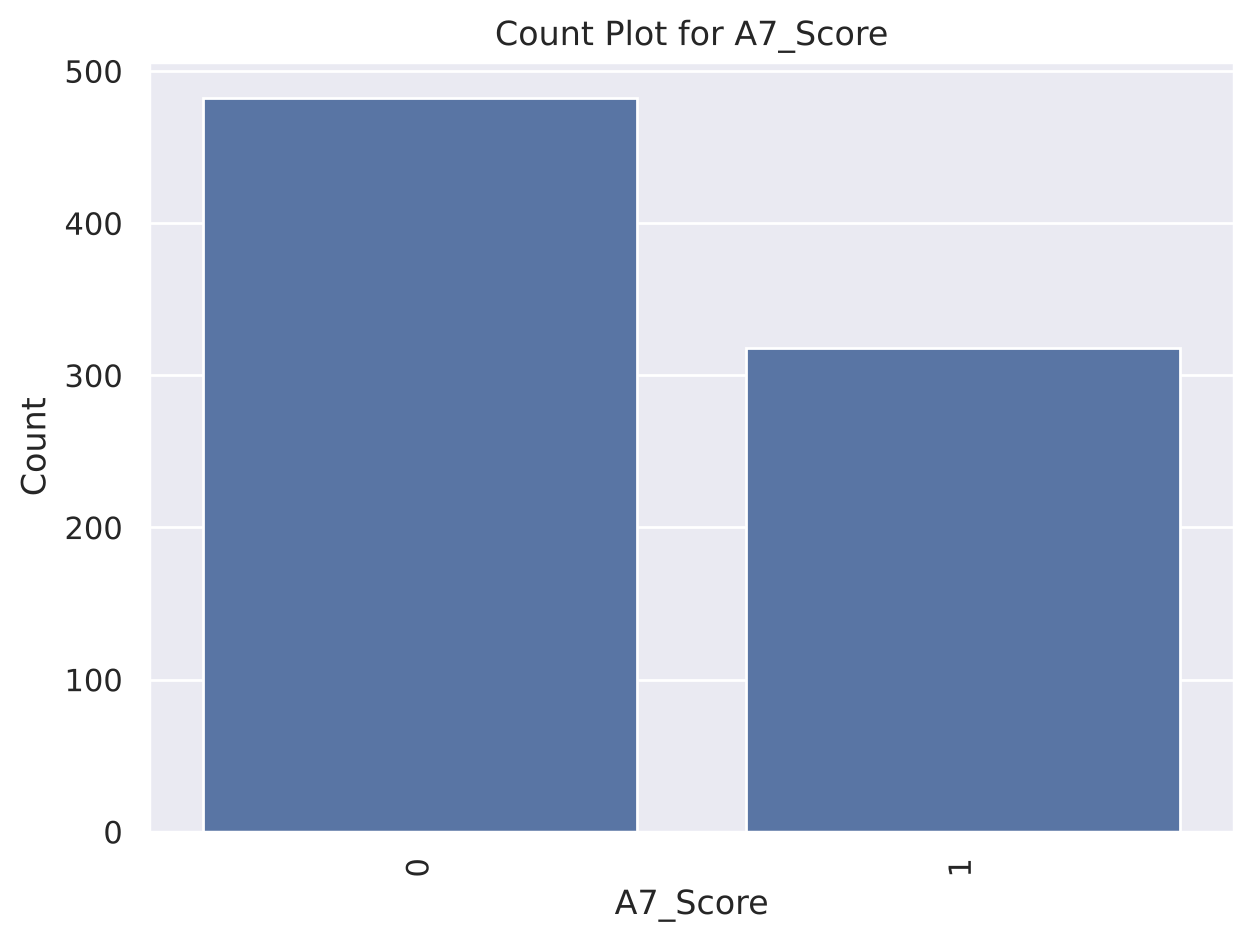

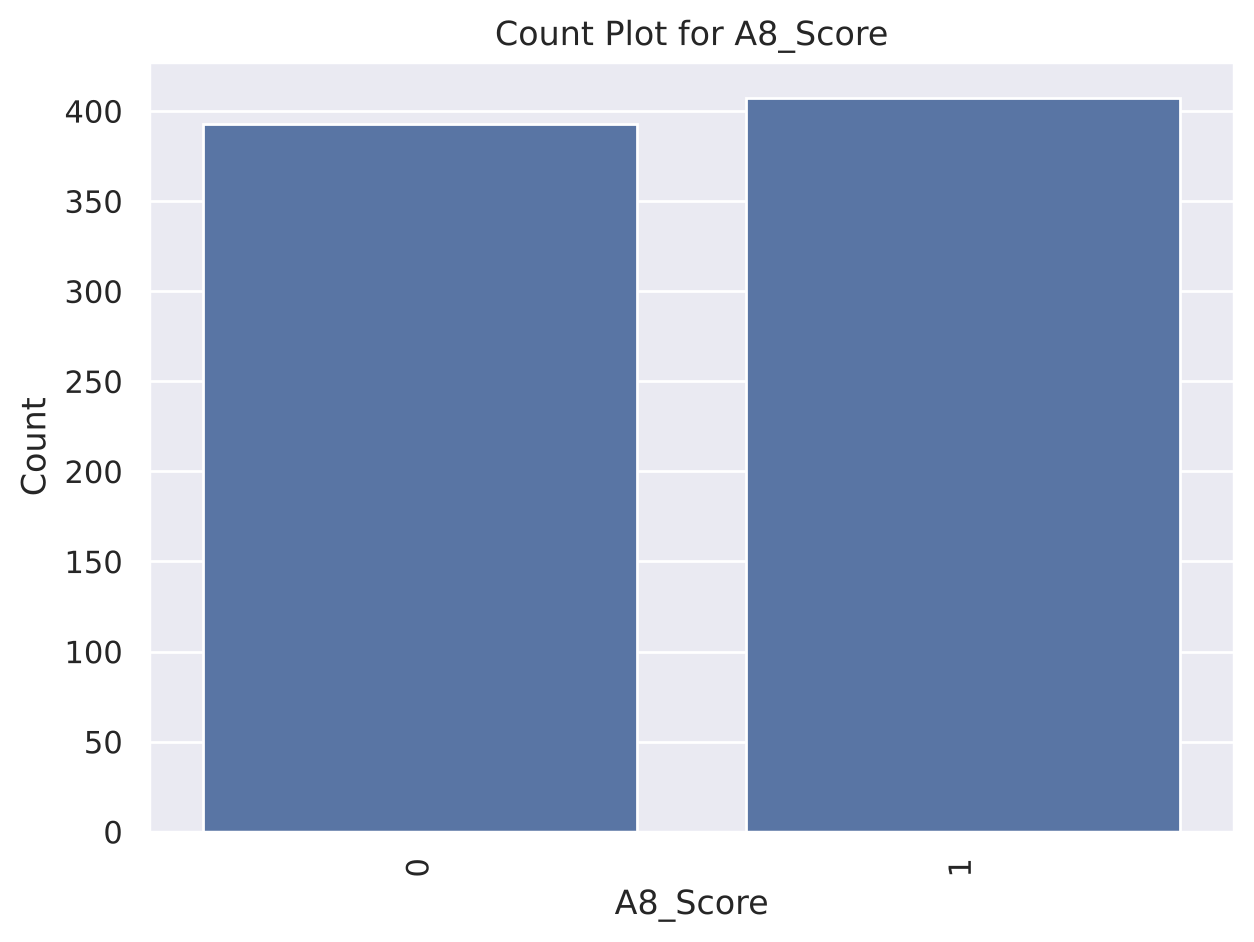

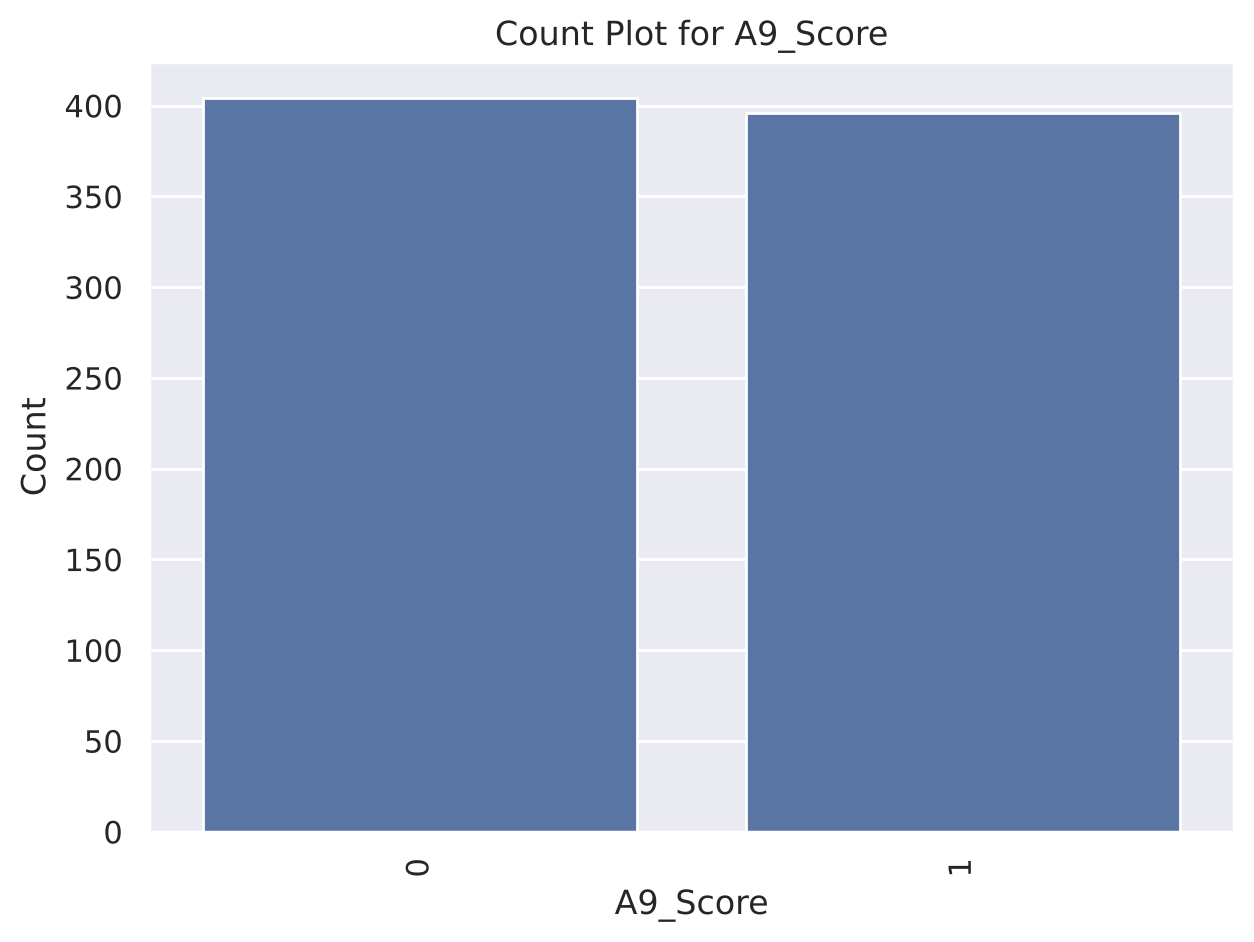

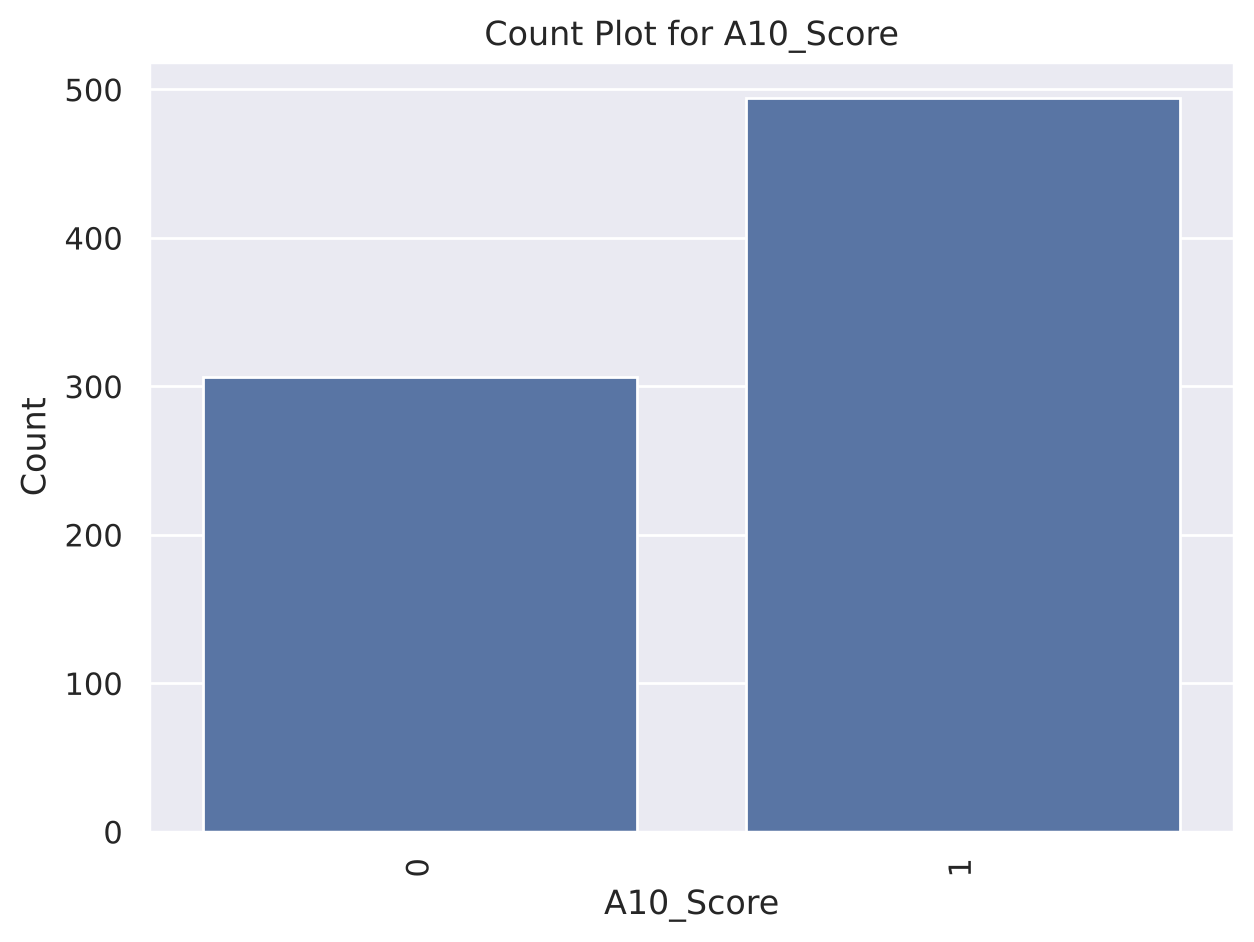

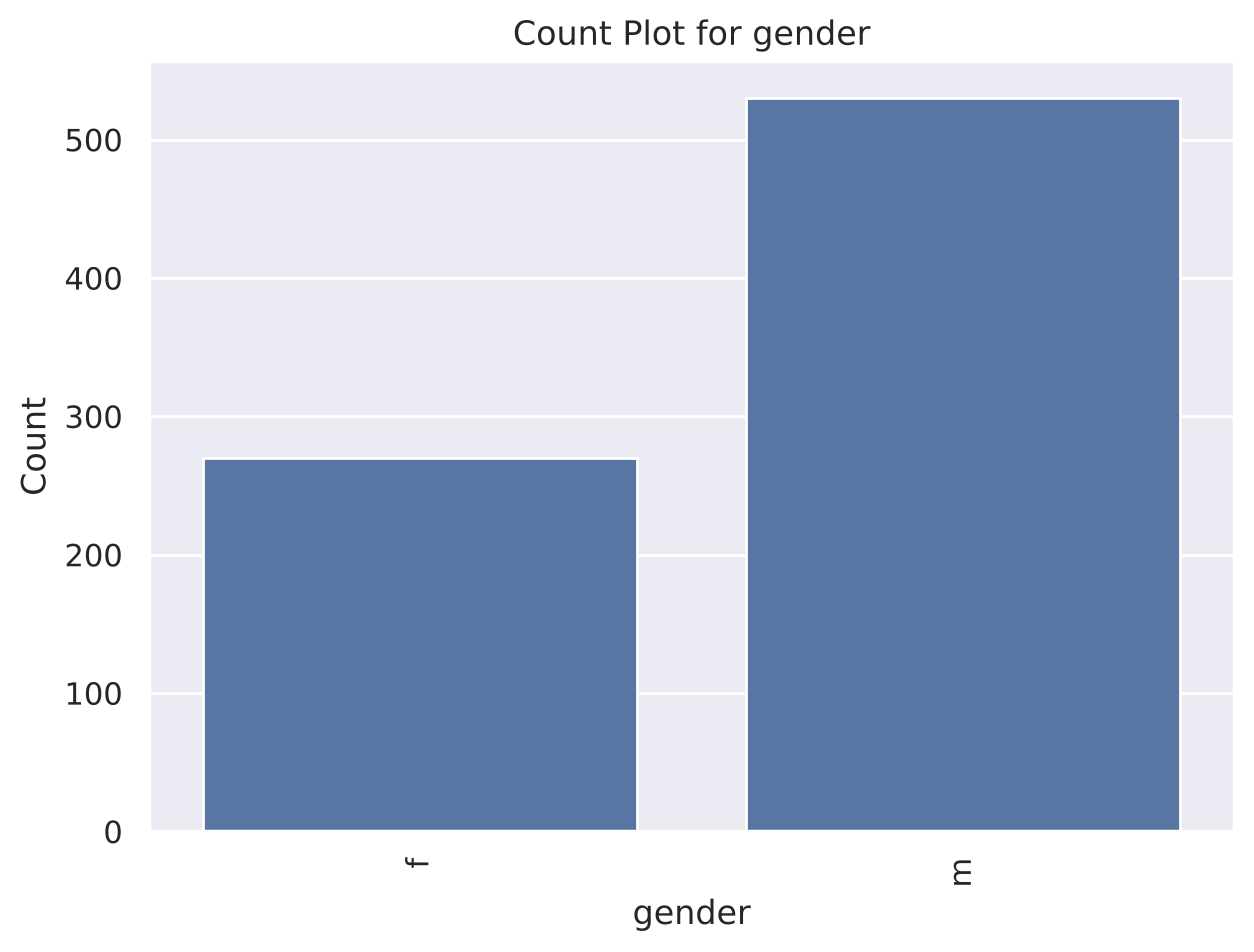

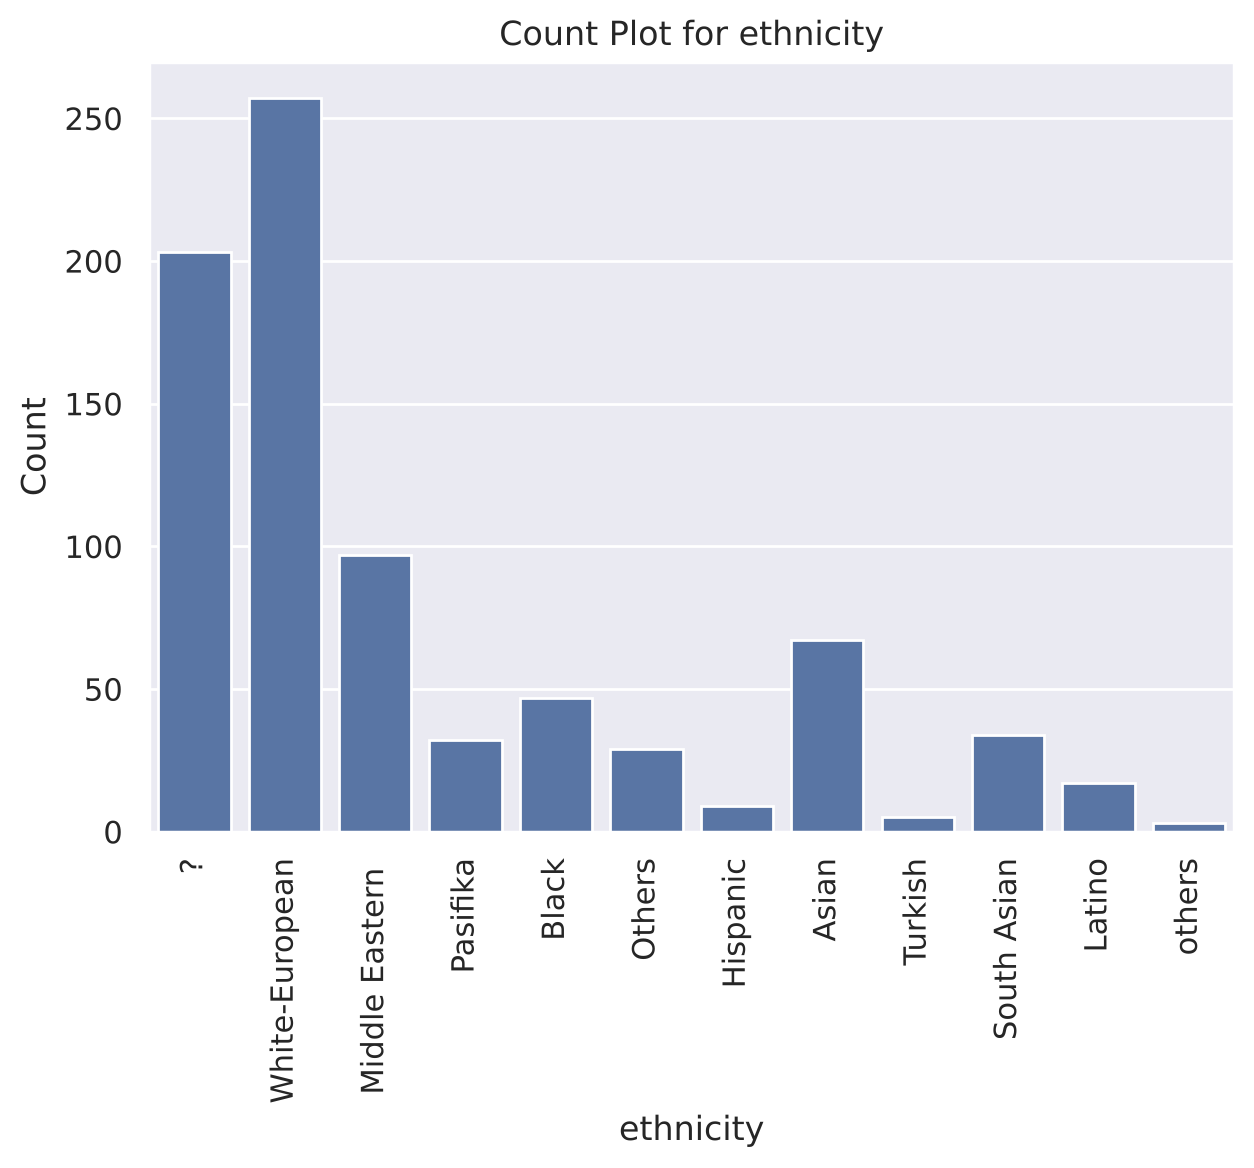

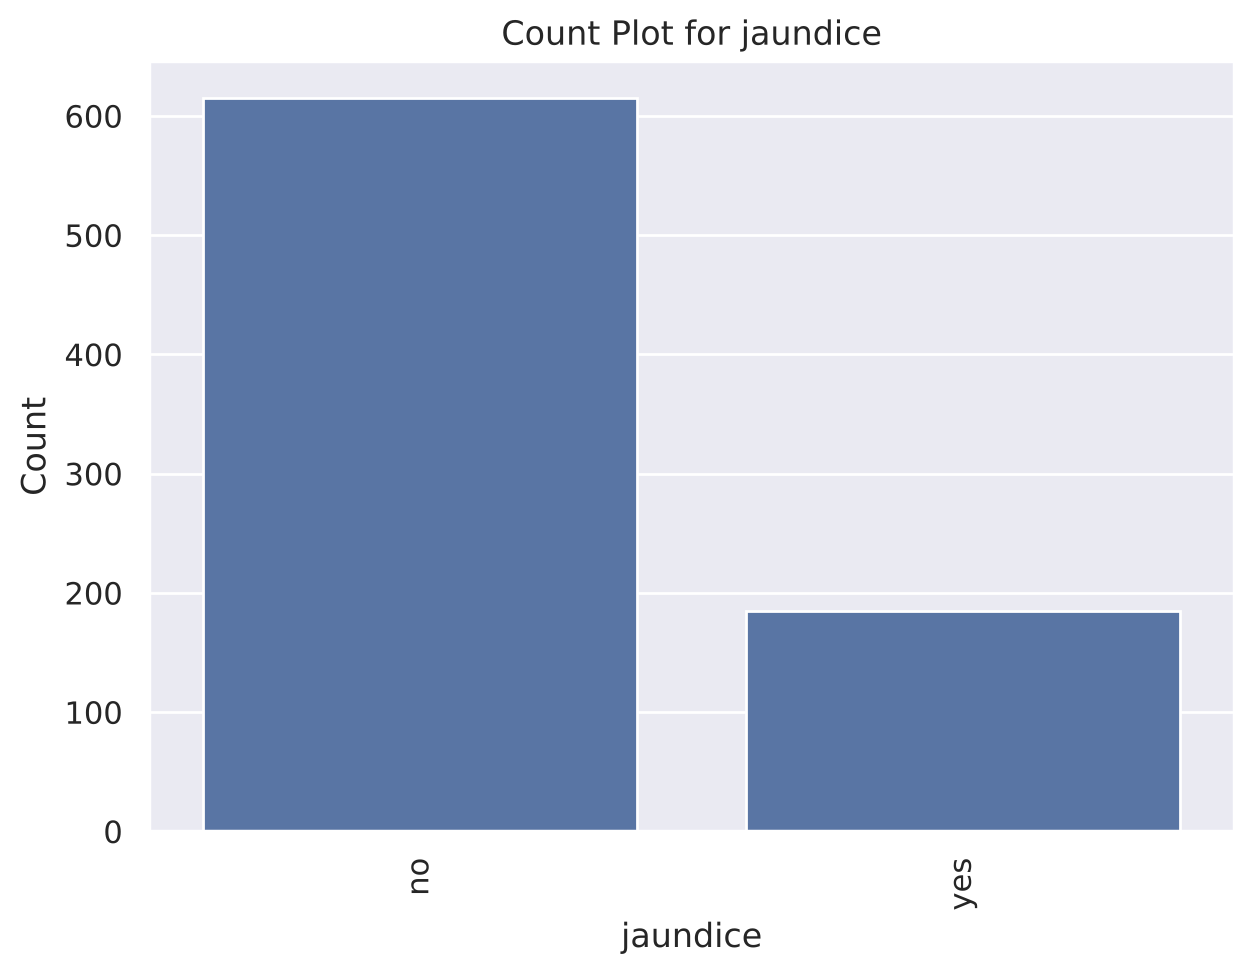

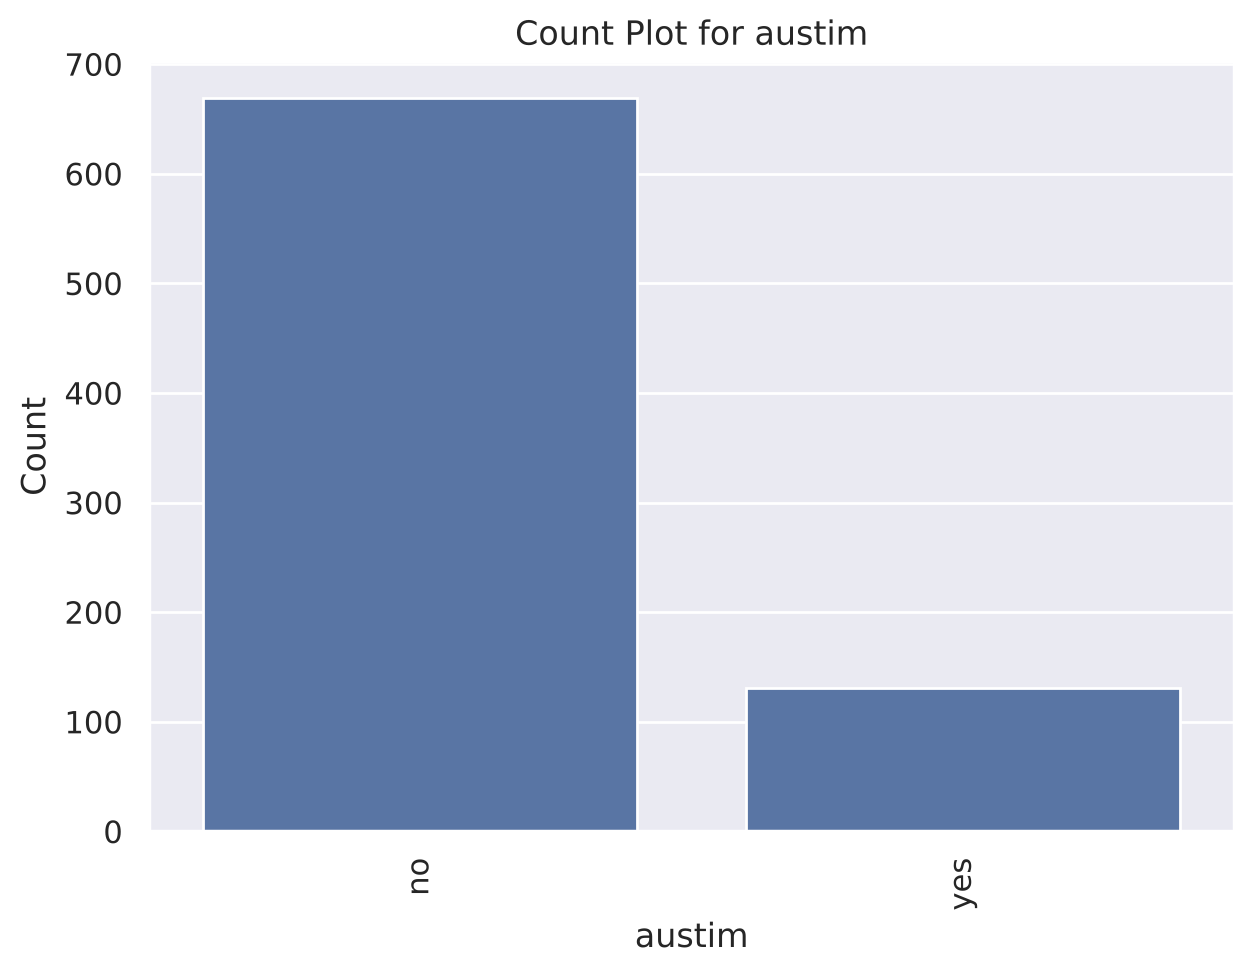

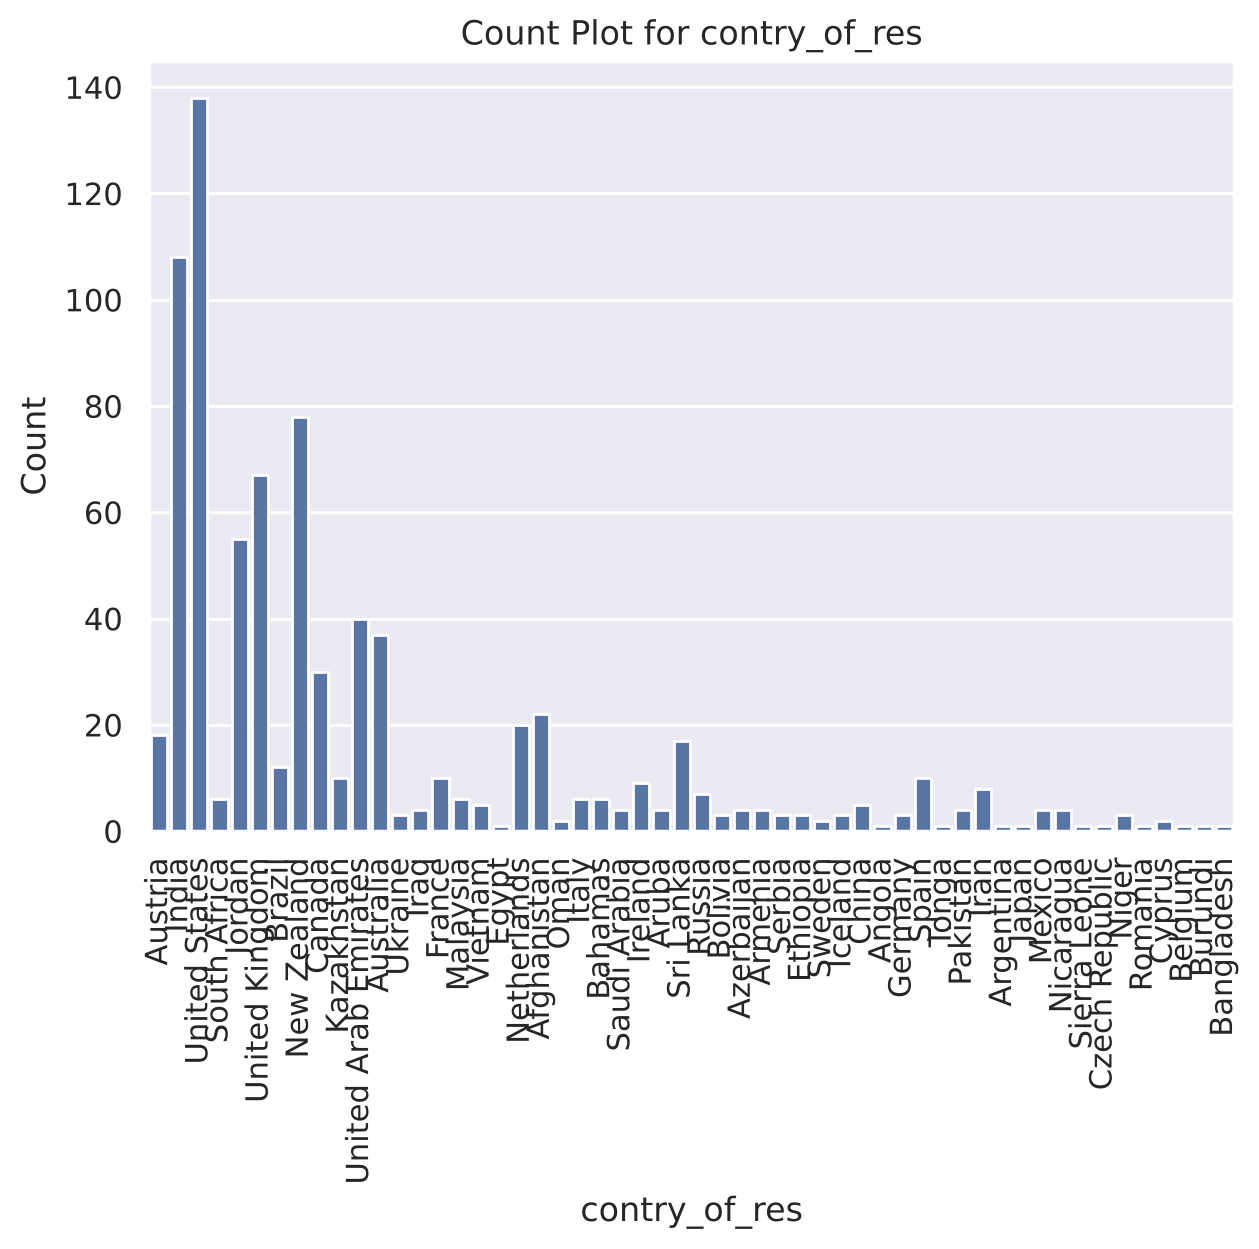

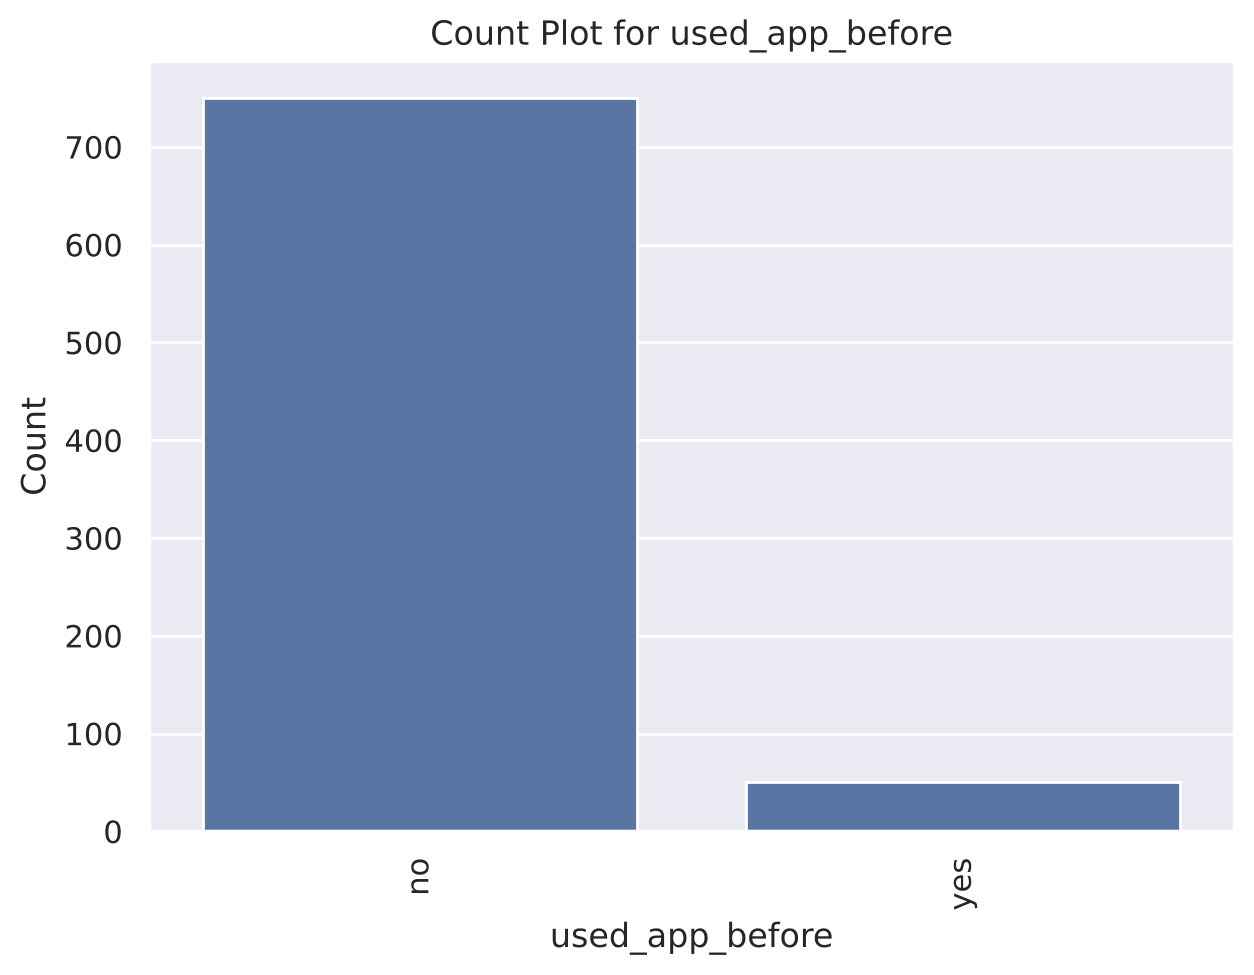

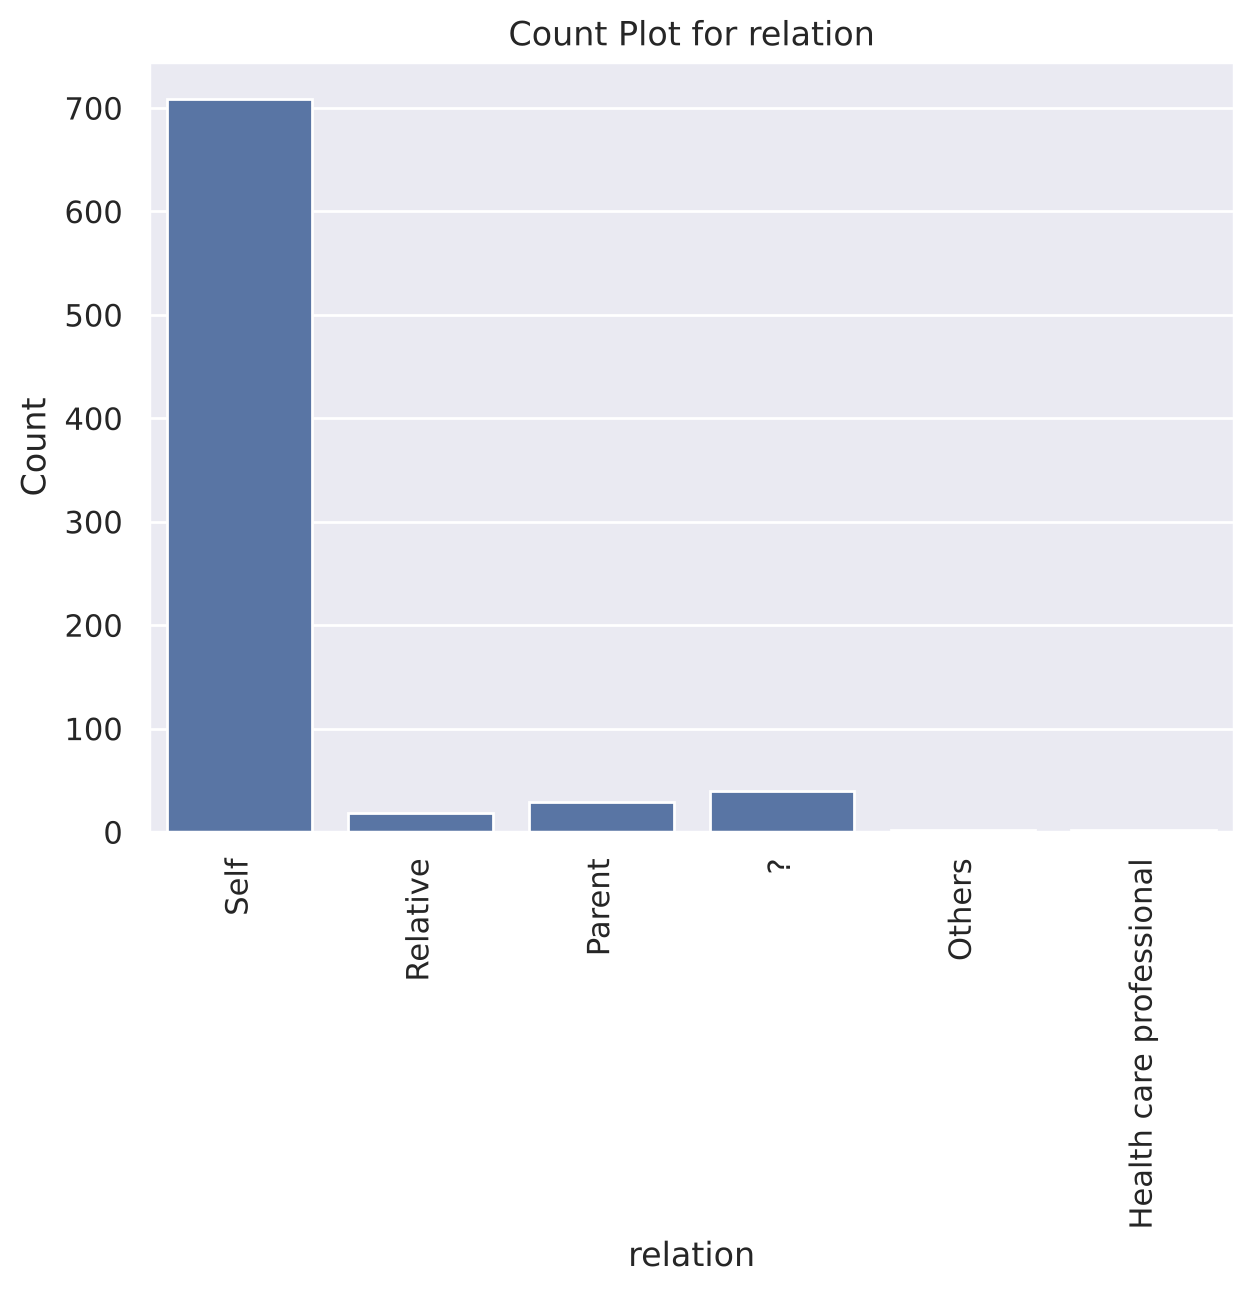

In [27]:
# count plots only for truly categorical columns
# (age and result are numerical -> already covered by the histograms and box plots above)
categorical_columns = ['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'relation']

for col in categorical_columns:
  plt.figure(figsize=(7, 5))
  sns.countplot(x=df[col])
  plt.title(f"Count Plot for {col}")
  plt.xlabel(col)
  plt.ylabel("Count")
  plt.xticks(rotation=90)
  plt.show()


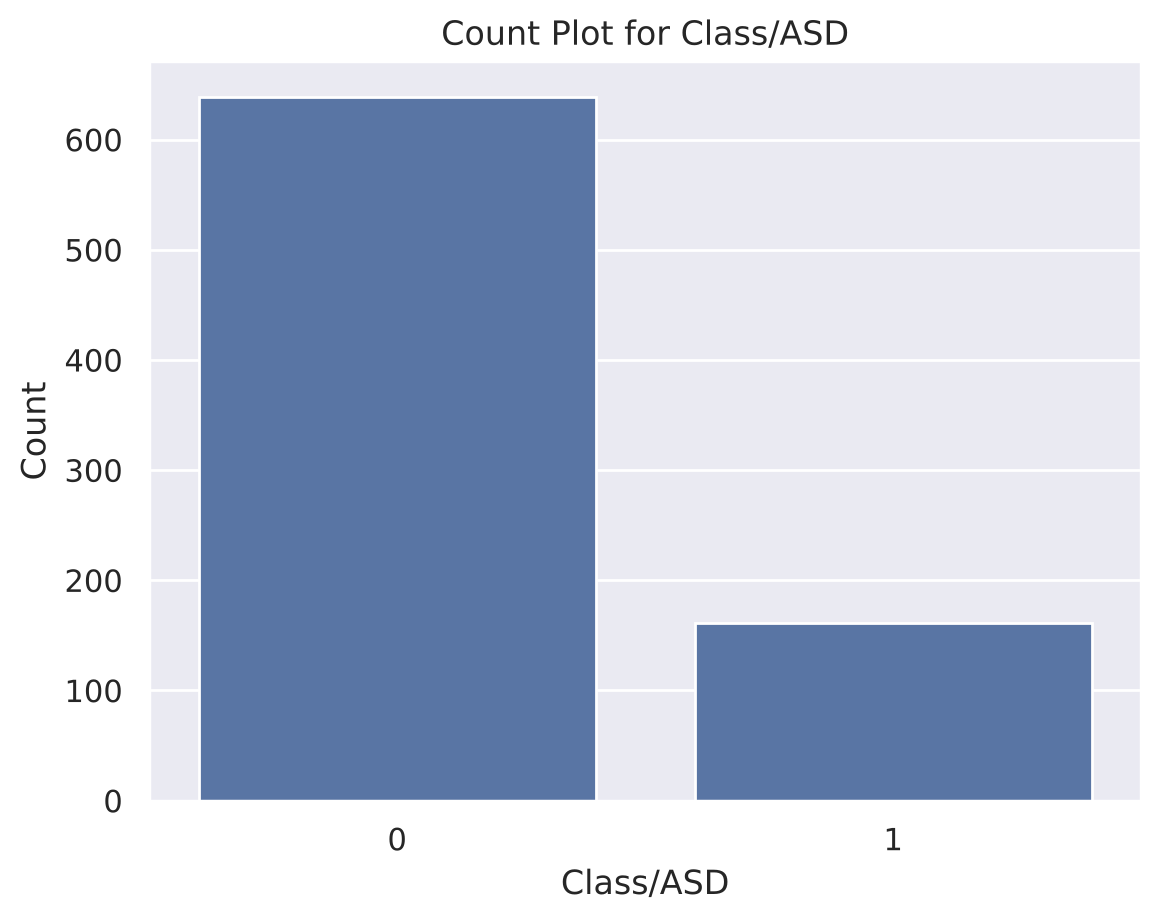

In [28]:
# countplot for target column (Class/ASD)
sns.countplot(x=df['Class/ASD'])
plt.title("Count Plot for Class/ASD")
plt.xlabel("Class/ASD")
plt.ylabel("Count")
plt.show()

In [29]:
df['Class/ASD'].value_counts()

Class/ASD
0    639
1    161
Name: count, dtype: int64

Handle missing values in relation & ethinicity column

In [30]:
# strip stray spaces first (e.g. 'Middle Eastern '), then merge '?' and 'others' into 'Others'
df['ethnicity'] = df['ethnicity'].str.strip().replace({"?":"Others", "others":"Others"})

In [31]:
df['ethnicity'].unique()

<ArrowStringArray>
[        'Others', 'White-European', 'Middle Eastern',       'Pasifika',
          'Black',       'Hispanic',          'Asian',        'Turkish',
    'South Asian',         'Latino']
Length: 10, dtype: str

In [32]:
df['relation'] = df['relation'].replace(
    {
        "?":"Others",
        "Relative":"Others",
        "Parent":"Others",
        "Health care professional":"Others"}

)

In [33]:
df['relation'].unique()

<ArrowStringArray>
['Self', 'Others']
Length: 2, dtype: str

In [34]:
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,f,Others,no,no,Austria,no,6.351166,Self,0
1,0,0,0,0,0,0,0,0,0,0,47,m,Others,no,no,India,no,2.255185,Self,0
2,1,1,1,1,1,1,1,1,1,1,7,m,White-European,no,yes,United States,no,14.851484,Self,1
3,0,0,0,0,0,0,0,0,0,0,23,f,Others,no,no,United States,no,2.276617,Self,0
4,0,0,0,0,0,0,0,0,0,0,43,m,Others,no,no,South Africa,no,-4.777286,Self,0


**Label Encoding**

In [35]:
# Identify columns with "object" datatype
object_columns = df.select_dtypes(include=['object']).columns

/tmp/ipykernel_275/2135870899.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_columns = df.select_dtypes(include=['object']).columns


In [36]:
print(object_columns)

Index(['gender', 'ethnicity', 'jaundice', 'austim', 'contry_of_res',
       'used_app_before', 'relation'],
      dtype='str')


In [37]:
# Initialise the dictionary to store the encoders
encoders = {}

# apply label encoding and store the encoders
for column in object_columns:
  label_encoder = LabelEncoder()
  df[column] = label_encoder.fit_transform(df[column])
  encoders[column] = label_encoder    # saving the encoder for this column

# save the encoders as a pickle file
with open("encoders.pkl", "wb") as f:
  pickle.dump(encoders,f)

In [38]:
encoders

{'gender': LabelEncoder(),
 'ethnicity': LabelEncoder(),
 'jaundice': LabelEncoder(),
 'austim': LabelEncoder(),
 'contry_of_res': LabelEncoder(),
 'used_app_before': LabelEncoder(),
 'relation': LabelEncoder()}

In [39]:
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,0,5,0,0,6,0,6.351166,1,0
1,0,0,0,0,0,0,0,0,0,0,47,1,5,0,0,23,0,2.255185,1,0
2,1,1,1,1,1,1,1,1,1,1,7,1,9,0,1,52,0,14.851484,1,1
3,0,0,0,0,0,0,0,0,0,0,23,0,5,0,0,52,0,2.276617,1,0
4,0,0,0,0,0,0,0,0,0,0,43,1,5,0,0,44,0,-4.777286,1,0


Bivariate Analysis

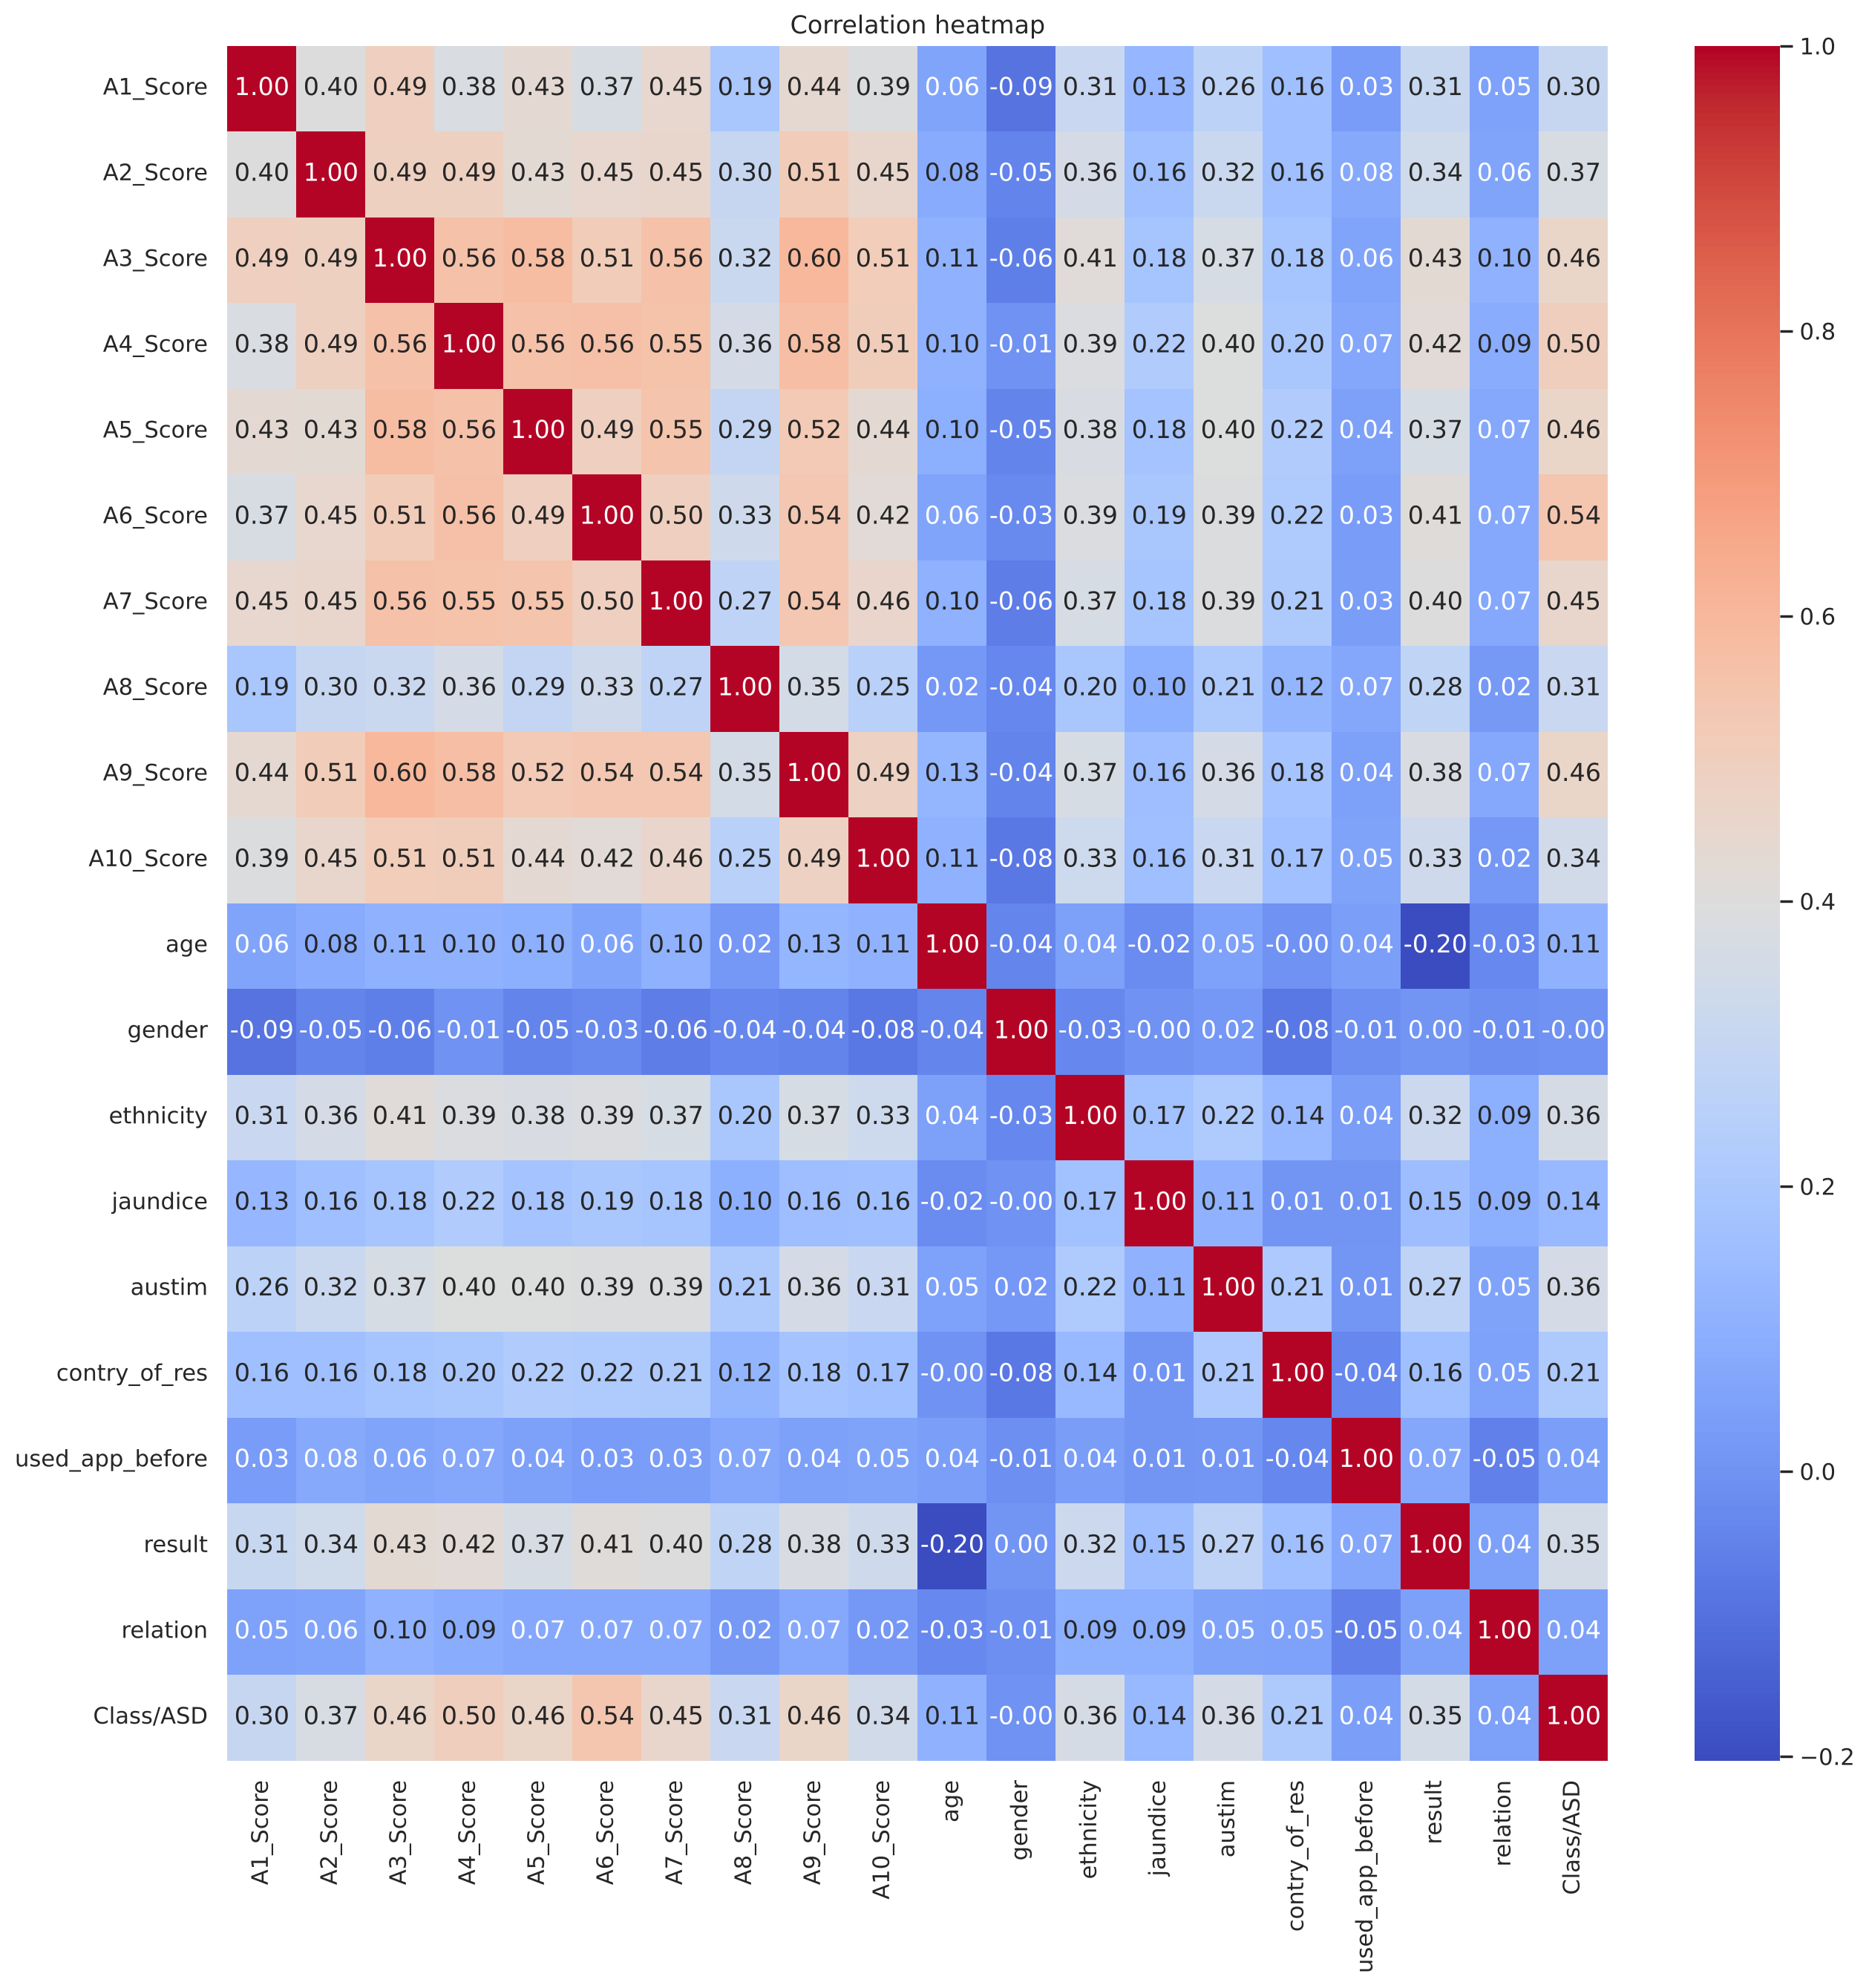

In [40]:
# Correlation matrix
plt.figure(figsize=(15,15))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm',fmt=".2f")
plt.title("Correlation heatmap")
plt.show()


**Insights from EDA :**

- There are some outliers in the numerical columns (age, results)
- There is a class imbalance in the target coumns.
- There is a class imbalance in the categorical features
- We don't have highly correlated column
- Performed label encoding and saved the encoders

**4. Data Preprocessing**

In [41]:
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,0,5,0,0,6,0,6.351166,1,0
1,0,0,0,0,0,0,0,0,0,0,47,1,5,0,0,23,0,2.255185,1,0
2,1,1,1,1,1,1,1,1,1,1,7,1,9,0,1,52,0,14.851484,1,1
3,0,0,0,0,0,0,0,0,0,0,23,0,5,0,0,52,0,2.276617,1,0
4,0,0,0,0,0,0,0,0,0,0,43,1,5,0,0,44,0,-4.777286,1,0


In [42]:
df.shape

(800, 20)

**Train Test Split**

In [43]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='str')

In [44]:
x = df.drop(columns=['Class/ASD', 'result'])
y = df['Class/ASD']
print(x.columns.tolist())

['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score', 'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender', 'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before', 'relation']


In [45]:
print(x)

     A1_Score  A2_Score  A3_Score  A4_Score  A5_Score  A6_Score  A7_Score  \
0           1         0         1         0         1         0         1   
1           0         0         0         0         0         0         0   
2           1         1         1         1         1         1         1   
3           0         0         0         0         0         0         0   
4           0         0         0         0         0         0         0   
..        ...       ...       ...       ...       ...       ...       ...   
795         0         1         0         0         0         0         0   
796         0         1         1         0         0         1         0   
797         0         0         0         0         0         0         0   
798         0         0         0         0         0         0         0   
799         0         1         0         0         0         0         0   

     A8_Score  A9_Score  A10_Score  age  gender  ethnicity  jaundice  austi

In [46]:
print(y)

0      0
1      0
2      1
3      0
4      0
      ..
795    0
796    0
797    0
798    0
799    0
Name: Class/ASD, Length: 800, dtype: int64


In [47]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [48]:
print(y_train.shape)
print(y_test.shape)

(640,)
(160,)


In [49]:
y_train.value_counts()

Class/ASD
0    511
1    129
Name: count, dtype: int64

In [50]:
y_test.value_counts()

Class/ASD
0    128
1     32
Name: count, dtype: int64

Handling the outliers in `age`. Bounds are learned from the **training set only**, and each column uses its own IQR.

In [51]:
def fit_outlier_bounds(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5*iqr, q3 + 1.5*iqr, series.median()

def apply_outlier_bounds(series, lower, upper, median):
    return series.where(series.between(lower, upper), median)

x_train, x_test = x_train.copy(), x_test.copy()
lower, upper, med = fit_outlier_bounds(x_train['age'])
print(f"age bounds: {lower:.1f} to {upper:.1f}, median {med}")
x_train['age'] = apply_outlier_bounds(x_train['age'], lower, upper, med)
x_test['age']  = apply_outlier_bounds(x_test['age'],  lower, upper, med)

age bounds: -11.5 to 64.5, median 24.0


**5. Model Training and Selection (leak-free)**

SMOTE is applied **inside an `imblearn` Pipeline**, so oversampling happens only on the training part of each CV fold and the validation folds stay real data. Models are compared with stratified 5-fold CV on metrics suited to an imbalanced target (F1, recall, precision, ROC-AUC), not accuracy alone. The test set is not used for selection.

In [52]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'f1': 'f1', 'recall': 'recall', 'precision': 'precision',
           'roc_auc': 'roc_auc', 'accuracy': 'accuracy'}

def make_pipe(clf):
    return ImbPipeline([('smote', SMOTE(random_state=42)), ('clf', clf)])

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss'),
}

Baseline comparison (default parameters):

In [53]:
rows = {}
for name, clf in models.items():
    cv = cross_validate(make_pipe(clf), x_train, y_train, cv=skf, scoring=scoring, n_jobs=-1)
    rows[name] = {m: cv[f'test_{m}'].mean() for m in scoring}
baseline = pd.DataFrame(rows).T.round(3)
baseline

,f1,recall,precision,roc_auc,accuracy
Decision Tree,0.538,0.550,0.537,0.713,0.809
Random Forest,0.626,0.674,0.593,0.900,0.838
XGBoost,0.603,0.658,0.564,0.877,0.825


**6. Hyperparameter Tuning** (RandomizedSearchCV, optimising F1 of the ASD class)

In [54]:
param_grid_dt = {
    'criterion':['gini','entropy'],
    'max_depth':[None, 5,10,15,20,30],
    'min_samples_split':[2,5,10,15],
    'min_samples_leaf':[1,2,4,8],
    'max_features':[None, 'sqrt','log2']
}
param_grid_rf = {
    'n_estimators': [50, 100, 200, 300, 500],
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 5, 10, 15, 20, 30],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False]
}
param_grid_xgb = {
    'n_estimators': [50, 100, 200, 300, 500],
    'max_depth': [3, 5, 7, 9, 11],
    'learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2, 0.3],
    'subsample': [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.2, 0.3, 0.4],
    'min_child_weight': [1, 3, 5, 7]
}
grids = {"Decision Tree": param_grid_dt, "Random Forest": param_grid_rf, "XGBoost": param_grid_xgb}

searches = {}
for name, clf in models.items():
    print(f"Tuning {name} ...")
    s = RandomizedSearchCV(
        make_pipe(clf), {f'clf__{k}': v for k, v in grids[name].items()},
        n_iter=20, cv=skf, scoring=scoring, refit='f1',
        random_state=42, n_jobs=-1)
    s.fit(x_train, y_train)          # original (un-SMOTEd) training data
    searches[name] = s

Tuning Decision Tree ...


Tuning Random Forest ...


Tuning XGBoost ...


In [55]:
# CV metrics of each model's best configuration
rows = {}
for name, s in searches.items():
    i = s.best_index_
    rows[name] = {m: s.cv_results_[f'mean_test_{m}'][i] for m in scoring}
tuned = pd.DataFrame(rows).T.round(3)
print(tuned)
for name, s in searches.items():
    print(f"\n{name}: {s.best_params_}")

                  f1  recall  precision  roc_auc  accuracy
Decision Tree  0.640   0.837      0.520    0.852     0.808
Random Forest  0.679   0.868      0.562    0.911     0.833
XGBoost        0.679   0.868      0.562    0.913     0.833

Decision Tree: {'clf__min_samples_split': 15, 'clf__min_samples_leaf': 2, 'clf__max_features': None, 'clf__max_depth': 5, 'clf__criterion': 'gini'}

Random Forest: {'clf__n_estimators': 50, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 1, 'clf__max_features': 'sqrt', 'clf__max_depth': 5, 'clf__criterion': 'entropy', 'clf__bootstrap': True}

XGBoost: {'clf__subsample': 0.7, 'clf__n_estimators': 300, 'clf__min_child_weight': 1, 'clf__max_depth': 3, 'clf__learning_rate': 0.01, 'clf__gamma': 0.3, 'clf__colsample_bytree': 0.8}


**Select the best model** by cross-validated F1 (ASD class); recall and ROC-AUC above act as tie-breakers.

In [56]:
# highest CV F1 wins; ROC-AUC breaks ties (the two models are tied on F1 here)
best_name = tuned.sort_values(['f1', 'roc_auc'], ascending=False).index[0]
best_pipe = searches[best_name].best_estimator_
print("Best model:", best_name)
print(tuned.loc[best_name])

Best model: XGBoost
f1           0.679
recall       0.868
precision    0.562
roc_auc      0.913
accuracy     0.833
Name: XGBoost, dtype: float64


**Decision threshold.** For screening, missing an ASD case costs more than a false alarm. The threshold is tuned on out-of-fold *training* predictions, not on the test set.

In [57]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, recall_score, precision_score

oof = cross_val_predict(best_pipe, x_train, y_train, cv=skf, method='predict_proba')[:, 1]
ths = np.arange(0.2, 0.81, 0.05)
tab = pd.DataFrame({
    'threshold': ths,
    'precision': [precision_score(y_train, oof >= t) for t in ths],
    'recall':    [recall_score(y_train, oof >= t) for t in ths],
    'f1':        [f1_score(y_train, oof >= t) for t in ths],
}).round(3)
print(tab.to_string(index=False))
best_threshold = round(float(tab.loc[tab['f1'].idxmax(), 'threshold']), 2)
print("\nChosen threshold:", best_threshold)

 threshold  precision  recall    f1
      0.20      0.419   0.969 0.585
      0.25      0.451   0.969 0.616
      0.30      0.484   0.961 0.644
      0.35      0.513   0.938 0.663
      0.40      0.531   0.922 0.674
      0.45      0.552   0.907 0.686
      0.50      0.554   0.868 0.677
      0.55      0.566   0.829 0.673
      0.60      0.583   0.791 0.671
      0.65      0.575   0.713 0.637
      0.70      0.601   0.667 0.632
      0.75      0.658   0.581 0.617
      0.80      0.667   0.450 0.537

Chosen threshold: 0.45


**7. Evaluation** (the test set is used once, only now)

In [58]:
from sklearn.metrics import roc_auc_score
proba_test = best_pipe.predict_proba(x_test)[:, 1]
for label, t in [("default 0.5", 0.5), (f"tuned {best_threshold}", best_threshold)]:
    pred = (proba_test >= t).astype(int)
    print(f"===== threshold {label} =====")
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print("Confusion Matrix:\n", confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred))
print("Test ROC-AUC:", round(roc_auc_score(y_test, proba_test), 4))

===== threshold default 0.5 =====
Accuracy: 0.825
Confusion Matrix:
 [[104  24]
 [  4  28]]
              precision    recall  f1-score   support

           0       0.96      0.81      0.88       128
           1       0.54      0.88      0.67        32

    accuracy                           0.82       160
   macro avg       0.75      0.84      0.77       160
weighted avg       0.88      0.82      0.84       160

===== threshold tuned 0.45 =====
Accuracy: 0.8187
Confusion Matrix:
 [[103  25]
 [  4  28]]
              precision    recall  f1-score   support

           0       0.96      0.80      0.88       128
           1       0.53      0.88      0.66        32

    accuracy                           0.82       160
   macro avg       0.75      0.84      0.77       160
weighted avg       0.88      0.82      0.83       160

Test ROC-AUC: 0.906


**8. Save the model for deployment** (classifier only; SMOTE is a training-time step)

In [59]:
import json
final_model = best_pipe.named_steps['clf']
with open('best_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)

with open('model_config.json', 'w') as f:
    json.dump({'model': best_name, 'threshold': best_threshold,
               'features': x.columns.tolist()}, f, indent=2)
print(best_name, best_threshold, x.columns.tolist())

XGBoost 0.45 ['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score', 'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender', 'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before', 'relation']
